# Evidencia Módulo 6
Ximena Pérez Escalante

A01751827

## Configuración del Entorno de PySpark

Este cuaderno configura un entorno de Apache Spark con Python (PySpark) en Google Colab.

Link al Dataset: https://www.kaggle.com/datasets/sobhanmoosavi/us-accidents

In [1]:
# Instalar Java 11, PySpark y findspark para la configuracion automatica de rutas
!apt-get install openjdk-11-jdk-headless -qq > /dev/null
!pip install -q pyspark findspark

E: Failed to fetch http://security.ubuntu.com/ubuntu/pool/universe/o/openjdk-lts/openjdk-11-jre-headless_11.0.32.1%2b1-1ubuntu1%7e24.04_amd64.deb  404  Not Found [IP: 91.189.92.24 80]
E: Failed to fetch http://security.ubuntu.com/ubuntu/pool/universe/o/openjdk-lts/openjdk-11-jdk-headless_11.0.32.1%2b1-1ubuntu1%7e24.04_amd64.deb  404  Not Found [IP: 91.189.92.24 80]
E: Unable to fetch some archives, maybe run apt-get update or try with --fix-missing?


> **Análisis**
>
> Spark está escrito en Scala y se ejecuta sobre la máquina virtual de Java (JVM), por eso el primer paso es instalar Java. Después se instalan **PySpark**, la interfaz de Python para Spark, y **findspark**, que ubica la instalación de Spark para que Python la pueda importar. Las banderas `-qq` y `-q` silencian los mensajes de instalación, así que una celda sin salida significa que la instalación terminó sin errores.

In [2]:
import os
import subprocess

# Detectar automáticamente la ruta real de Java activa en el sistema
try:
    java_path = subprocess.check_output("readlink -f $(which java)", shell=True).decode().strip()
    # Obtener el directorio base de la instalacion de JDK (quitando /bin/java)
    java_home = java_path.split("/bin/")[0]
    os.environ["JAVA_HOME"] = java_home
    print(f"JAVA_HOME detectado y configurado automáticamente en: {java_home}")
except Exception as e:
    # Ruta por defecto segura para Ubuntu en Colab si falla la autodeteccion
    os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-21-openjdk-amd64"
    print("Asignada ruta por defecto de Java 21.")

JAVA_HOME detectado y configurado automáticamente en: /usr/lib/jvm/java-21-openjdk-amd64


> **Análisis**
>
> La celda detecta la ruta real de Java activa en el sistema en lugar de escribirla a mano. La salida muestra que Colab usa **Java 21**, aunque la celda anterior instala Java 11: Colab ya trae una versión más reciente preinstalada y es la que queda activa. Esto no es un problema, porque PySpark 4 requiere Java 17 o superior. Si se hubiera forzado Java 11, la sesión de Spark no habría podido iniciar.

## Inicializar la Sesión de Spark

Crear una sesión de Spark (`SparkSession`) para comprobar que el entorno está correctamente configurado.

In [3]:
import os
import sys
import subprocess

# Forzar la detección dinámica correcta de JAVA_HOME
try:
    java_path = subprocess.check_output("readlink -f $(which java)", shell=True).decode().strip()
    os.environ["JAVA_HOME"] = java_path.split("/bin/")[0]
except Exception:
    os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-21-openjdk-amd64"

os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

# Inicializar findspark
try:
    import findspark
    findspark.init()
except Exception as e:
    print(f"Nota sobre findspark: {e}")

from pyspark.sql import SparkSession

# Detener contextos previos para liberar puertos
try:
    from pyspark import SparkContext
    if SparkContext._active_spark_context is not None:
        SparkContext._active_spark_context.stop()
except Exception:
    pass

# Crear la sesión de Spark de forma segura
try:
    spark = SparkSession.builder \
        .appName("Colab_PySpark_Env") \
        .master("local[*]") \
        .config("spark.driver.memory", "8g") \
        .config("spark.driver.host", "127.0.0.1") \
        .config("spark.driver.bindAddress", "127.0.0.1") \
        .getOrCreate()

    print("¡Sesión de Spark creada con éxito!")
    display(spark)
except Exception as err:
    print("Error al inicializar Spark:", err)

¡Sesión de Spark creada con éxito!


> **Análisis**
>
> La sesión de Spark se crea en modo **local[*]**: el *driver* y los *executors* corren en la misma máquina de Colab y usan todos sus núcleos disponibles. Se asignan 8 GB de memoria al *driver*, porque con el valor por defecto (1 GB) Spark no alcanza a procesar los 2.85 GB del dataset completo. La salida `SparkSession` confirma que el entorno quedó listo para trabajar.

## Dataset

Se seleccionó el Dataset de Kaggle llamado "US Accidents (2016 - 2023)". Es un archivo .csv (datos tabulares) que pesa en total 2.85GB.

In [4]:
path = 'MyDrive/BigData_Dataset'



> **Análisis**
>
> Se define la carpeta de Google Drive donde está guardado el dataset. Separar la ruta en una variable facilita cambiarla sin modificar el código de carga.

### Montar Google Drive y Cargar el Dataset con PySpark

Primero montaremos Google Drive para acceder a la ruta indicada y luego utilizaremos `spark.read` para cargar el archivo CSV de 2.85GB de forma eficiente.

In [5]:
from google.colab import drive
# Montar Google Drive en /content/drive
drive.mount('/content/drive')

Mounted at /content/drive


> **Análisis**
>
> Montar Google Drive permite que Spark lea el CSV directamente desde la nube, sin tener que subirlo a Colab en cada sesión. El mensaje indica que Drive ya estaba montado, por lo que no fue necesario volver a autorizar el acceso.

In [6]:
import os
import glob

# Ajustar la ruta para usar el prefijo de Google Drive montado
full_path = f"/content/drive/{path}"

# Verificar si es un directorio y buscar archivos CSV dentro
if os.path.isdir(full_path):
    csv_files = glob.glob(os.path.join(full_path, "*.csv"))
    if csv_files:
        print(f"Directorio detectado. Cargando el primer archivo CSV encontrado: {csv_files[0]}")
        target_path = csv_files[0]
    else:
        raise FileNotFoundError(f"No se encontraron archivos .csv en el directorio: {full_path}")
else:
    target_path = full_path

print(f"Cargando dataset desde: {target_path}")

# Cargar el dataset con PySpark
df_accidents = spark.read.csv(target_path, header=True, inferSchema=True)

# Mostrar el esquema para comprobar las columnas cargadas
df_accidents.printSchema()

Directorio detectado. Cargando el primer archivo CSV encontrado: /content/drive/MyDrive/BigData_Dataset/US_Accidents_March23.csv
Cargando dataset desde: /content/drive/MyDrive/BigData_Dataset/US_Accidents_March23.csv
root
 |-- ID: string (nullable = true)
 |-- Source: string (nullable = true)
 |-- Severity: integer (nullable = true)
 |-- Start_Time: timestamp (nullable = true)
 |-- End_Time: timestamp (nullable = true)
 |-- Start_Lat: double (nullable = true)
 |-- Start_Lng: double (nullable = true)
 |-- End_Lat: double (nullable = true)
 |-- End_Lng: double (nullable = true)
 |-- Distance(mi): double (nullable = true)
 |-- Description: string (nullable = true)
 |-- Street: string (nullable = true)
 |-- City: string (nullable = true)
 |-- County: string (nullable = true)
 |-- State: string (nullable = true)
 |-- Zipcode: string (nullable = true)
 |-- Country: string (nullable = true)
 |-- Timezone: string (nullable = true)
 |-- Airport_Code: string (nullable = true)
 |-- Weather_Timest

> **Análisis**
>
> El dataset se carga con `inferSchema=True`, por lo que Spark revisa los datos para asignar a cada columna su tipo: las fechas se reconocen como *timestamp*, las mediciones de clima como *double* y los indicadores viales (Amenity, Crossing, Stop, etc.) como *boolean*. El esquema confirma **46 columnas** que cubren cuatro grupos de información: identificación y severidad del accidente, ubicación, condiciones del clima y características de la vía.
>
> Zipcode se lee como texto y no como número, lo cual es correcto: así se conservan los ceros a la izquierda y el formato extendido ZIP+4 (por ejemplo, 43068-3402).

In [7]:
# Mostrar los primeros 5 registros de forma legible
df_accidents.show(5, truncate=True)

+---+-------+--------+-------------------+-------------------+-----------------+------------------+-------+-------+------------+--------------------+--------------------+------------+----------+-----+----------+-------+----------+------------+-------------------+--------------+-------------+-----------+------------+--------------+--------------+---------------+-----------------+-----------------+-------+-----+--------+--------+--------+-------+-------+----------+-------+-----+---------------+--------------+------------+--------------+--------------+-----------------+---------------------+
| ID| Source|Severity|         Start_Time|           End_Time|        Start_Lat|         Start_Lng|End_Lat|End_Lng|Distance(mi)|         Description|              Street|        City|    County|State|   Zipcode|Country|  Timezone|Airport_Code|  Weather_Timestamp|Temperature(F)|Wind_Chill(F)|Humidity(%)|Pressure(in)|Visibility(mi)|Wind_Direction|Wind_Speed(mph)|Precipitation(in)|Weather_Condition|Ameni

> **Análisis**
>
> La vista previa ya anticipa algunos problemas de calidad que se analizan más adelante:
>
> - **End_Lat** y **End_Lng** aparecen como NULL en los primeros registros.
> - **Wind_Chill(F)**, **Wind_Speed(mph)** y **Precipitation(in)** también tienen valores faltantes.
> - **Zipcode** mezcla el formato de 5 dígitos con el formato extendido (43068-3402).
>
> También se observa que Severity va de 1 a 4 y que la columna Description contiene texto libre que describe el accidente.

## Configuración de PySpark MLlib

La biblioteca de Machine Learning de Spark (MLlib) se incluye de forma nativa en la instalación de PySpark. A continuación, se presenta una prueba rápida de inicialización importando componentes clave para la creación de modelos.

In [8]:
from pyspark.ml.feature import VectorAssembler, StringIndexer
from pyspark.ml.classification import LogisticRegression
from pyspark.ml import Pipeline
from pyspark.sql import SparkSession

# Recuperar o crear la sesión de Spark para asegurar que 'spark' esté definido
spark = SparkSession.builder.getOrCreate()

print("¡Librerías de MLlib importadas correctamente!")

# Crearemos un DataFrame de ejemplo rápido para verificar el flujo de trabajo de MLlib
demo_data = spark.createDataFrame([
    (1.0, 2.0, "A"),
    (2.0, 1.0, "B"),
    (1.5, 1.8, "A"),
    (3.0, 3.5, "B")
], ["Feature1", "Feature2", "Label"]
)

# 1. Convertir la etiqueta categórica a numérica
indexer = StringIndexer(inputCol="Label", outputCol="indexedLabel")

# 2. Ensamblar las características en un solo vector (requerido por MLlib)
assembler = VectorAssembler(inputCols=["Feature1", "Feature2"], outputCol="features")

# 3. Definir un modelo básico (Regresión Logística)
lr = LogisticRegression(featuresCol="features", labelCol="indexedLabel")

# 4. Crear y ajustar un Pipeline
pipeline = Pipeline(stages=[indexer, assembler, lr])
model = pipeline.fit(demo_data)

print("MLlib está configurado y el pipeline de prueba se ejecutó con éxito.")
predictions = model.transform(demo_data)
display(predictions.select("features", "Label", "indexedLabel", "rawPrediction", "probability", "prediction"))

¡Librerías de MLlib importadas correctamente!
MLlib está configurado y el pipeline de prueba se ejecutó con éxito.


DataFrame[features: vector, Label: string, indexedLabel: double, rawPrediction: vector, probability: vector, prediction: double]

> **Análisis**
>
> Esta prueba con datos de ejemplo confirma que los componentes de MLlib (StringIndexer, VectorAssembler, Pipeline y un clasificador) funcionan correctamente en el entorno. Es la misma estructura de Pipeline que se usa en la sección 8 con el dataset real.

## Exploración y limpieza de datos

En esta sección se revisa la calidad del dataset (valores faltantes, duplicados, columnas constantes, valores fuera de rango e inconsistencias) y después se aplica la limpieza. Todo se hace con PySpark para trabajar con el archivo completo, sin muestrear.

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import functions as F
from pyspark.sql import types as T
from pyspark import StorageLevel

# Reutilizar el DataFrame cargado arriba; si el entorno se reinició, volver a cargarlo
try:
    df_accidents
except NameError:
    ruta_csv = "/content/drive/MyDrive/BigData_Dataset/US_Accidents_March23.csv"
    df_accidents = spark.read.csv(ruta_csv, header=True, inferSchema=True)

# Guardar en memoria/disco para no releer el CSV de 2.85 GB en cada operación
df = df_accidents.persist(StorageLevel.MEMORY_AND_DISK)
n_total = df.count()

tipos = pd.Series([f.dataType.simpleString() for f in df.schema.fields]).value_counts()
print(f"Registros: {n_total:,}")
print(f"Columnas:  {len(df.columns)}")
print("\nColumnas por tipo de dato:")
print(tipos.to_string())

Registros: 7,728,394
Columnas:  46

Columnas por tipo de dato:
string       17
boolean      13
double       12
timestamp     3
int           1


> **Análisis**
>
> El dataset tiene **7,728,394 registros y 46 columnas**. Predominan las columnas de texto (17) y las booleanas (13), seguidas de las numéricas (12 *double* y 1 entera) y las de fecha (3).
>
> El DataFrame se guarda en caché con `persist(MEMORY_AND_DISK)`. Spark evalúa de forma perezosa (*lazy evaluation*): sin la caché, cada operación de las siguientes secciones volvería a leer y procesar el CSV completo desde Drive.

### 1. Valores faltantes

Se cuentan como faltantes los valores NULL, los NaN en columnas numéricas y las cadenas vacías en columnas de texto.

22 de 46 columnas tienen valores faltantes



,columna,nulos,porcentaje
0,End_Lng,3402762,44.03
1,End_Lat,3402762,44.03
2,Precipitation(in),2203586,28.51
3,Wind_Chill(F),1999019,25.87
4,Wind_Speed(mph),571233,7.39
5,Visibility(mi),177098,2.29
6,Wind_Direction,175206,2.27
7,Humidity(%),174144,2.25
8,Weather_Condition,173459,2.24
9,Temperature(F),163853,2.12


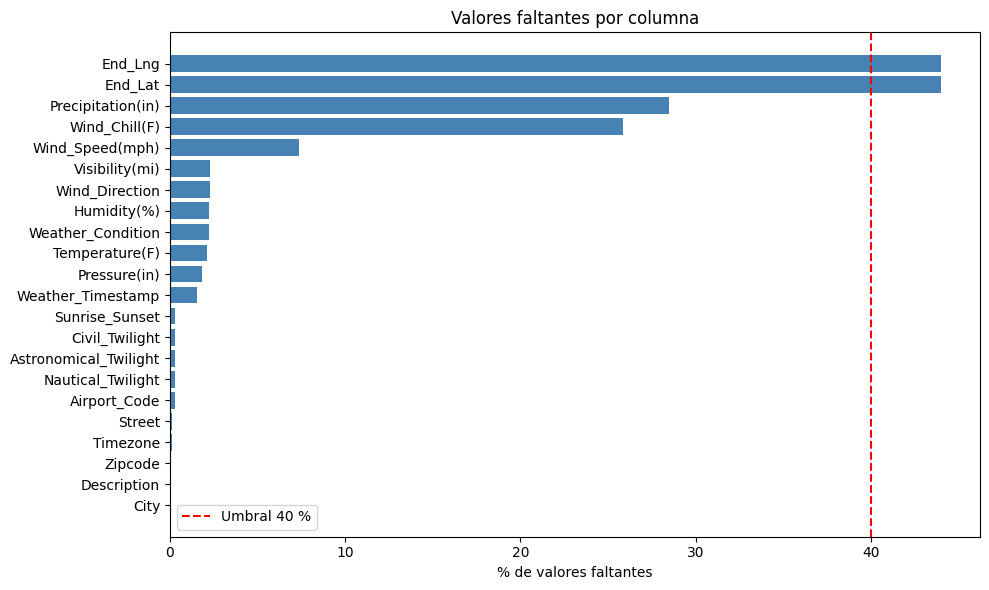

In [10]:
def conteo_nulos(data, total):
    """Regresa un DataFrame de pandas con el número y porcentaje de faltantes por columna."""
    exprs = []
    for campo in data.schema.fields:
        c = F.col(campo.name)
        cond = c.isNull()
        if isinstance(campo.dataType, (T.DoubleType, T.FloatType)):
            cond = cond | F.isnan(c)
        elif isinstance(campo.dataType, T.StringType):
            cond = cond | (F.trim(c) == "")
        exprs.append(F.sum(F.when(cond, 1).otherwise(0)).alias(campo.name))
    fila = data.agg(*exprs).collect()[0].asDict()
    res = pd.DataFrame({"columna": list(fila.keys()), "nulos": list(fila.values())})
    res["porcentaje"] = (res["nulos"] / total * 100).round(2)
    return res.sort_values("porcentaje", ascending=False).reset_index(drop=True)

nulos_pdf = conteo_nulos(df, n_total)
con_nulos = nulos_pdf[nulos_pdf["nulos"] > 0]
print(f"{len(con_nulos)} de {len(df.columns)} columnas tienen valores faltantes\n")
display(con_nulos)

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(con_nulos["columna"], con_nulos["porcentaje"], color="steelblue")
ax.axvline(40, color="red", linestyle="--", label="Umbral 40 %")
ax.invert_yaxis()
ax.set_xlabel("% de valores faltantes")
ax.set_title("Valores faltantes por columna")
ax.legend()
plt.tight_layout()
plt.show()

> **Análisis**
>
> **22 de las 46 columnas** tienen valores faltantes, pero en proporciones muy distintas:
>
> - **End_Lat y End_Lng (44 %)** son las únicas que superan el umbral de 40 %. Les faltan exactamente 3,402,762 valores, y el número de registros que sí los tienen (4,325,632) coincide con el número de registros de **Source1**. Es decir, solo uno de los tres proveedores reporta la ubicación final del accidente.
> - **Precipitation (28.5 %)** y **Wind_Chill (25.9 %)** dependen de que la estación meteorológica más cercana reporte esa medición. Muchas estaciones no lo hacen, sobre todo cuando no llueve o no hace frío.
> - Las demás variables de clima tienen entre 1.5 % y 7.4 % de faltantes.
> - Las cuatro columnas de crepúsculo tienen exactamente los mismos 23,246 faltantes, lo que indica que se trata de los mismos registros sin información de hora del día.
> - Las columnas de ubicación (Street, City, Zipcode, Timezone, Airport_Code) tienen menos de 0.3 %.
>
> La gráfica deja claro que solo dos columnas cruzan la línea roja del umbral, por lo que la gran mayoría de la información se puede conservar.

### 2. Registros duplicados

Se revisan tres casos: IDs repetidos, filas idénticas en todas las columnas, y filas idénticas ignorando el ID (el mismo accidente registrado dos veces con distinto identificador).

In [11]:
ids_repetidos = n_total - df.select("ID").distinct().count()
# Si los IDs son únicos, no puede haber filas idénticas en todas las columnas
dup_exactos = 0 if ids_repetidos == 0 else n_total - df.dropDuplicates().count()

cols_sin_id = [c for c in df.columns if c != "ID"]
dup_sin_id = n_total - df.dropDuplicates(cols_sin_id).count()

print(f"IDs repetidos:                         {ids_repetidos:,}")
print(f"Filas duplicadas (todas las columnas): {dup_exactos:,}")
print(f"Filas duplicadas (ignorando el ID):    {dup_sin_id:,} ({dup_sin_id / n_total:.2%})")

if dup_sin_id > 0:
    print("\nEjemplos de registros repetidos con distinto ID:")
    (df.groupBy(cols_sin_id)
       .agg(F.count("*").alias("veces"), F.collect_list("ID").alias("IDs"))
       .filter("veces > 1")
       .select("IDs", "veces", "Start_Time", "City", "State", "Description")
       .show(5, truncate=50))

IDs repetidos:                         0
Filas duplicadas (todas las columnas): 0
Filas duplicadas (ignorando el ID):    117,695 (1.52%)

Ejemplos de registros repetidos con distinto ID:
+----------------------+-----+-------------------+-------------+-----+--------------------------------------------------+
|                   IDs|veces|         Start_Time|         City|State|                                       Description|
+----------------------+-----+-------------------+-------------+-----+--------------------------------------------------+
|[A-7122206, A-7122219]|    2|2020-03-19 15:16:24|          Rye|   NY|At I-95/New England Thwy (Rye) - Accident. Hard...|
|[A-7126217, A-7126221]|    2|2020-03-20 08:21:59|  New Orleans|   LA|                              At US-90 - Accident.|
|[A-7126339, A-7126343]|    2|2020-03-20 16:21:03|  Baton Rouge|   LA|                 At US-190/Airline Hwy - Accident.|
|[A-7129408, A-7129410]|    2|2020-03-22 08:02:01|    Lafayette|   CA|At Acalanes

> **Análisis**
>
> Todos los IDs son únicos, por lo que no hay filas idénticas en todas sus columnas. Sin embargo, al ignorar el ID aparecen **117,695 registros duplicados (1.52 %)**: el mismo accidente, con la misma hora, ubicación y descripción, registrado dos veces con distinto identificador.
>
> Los ejemplos tienen IDs muy cercanos entre sí (A-7122206 y A-7122219), lo que sugiere que el mismo evento llegó dos veces durante la recolección de datos. Si no se eliminan, estos registros inflarían los conteos del dashboard y harían que el modelo viera algunos casos dos veces.

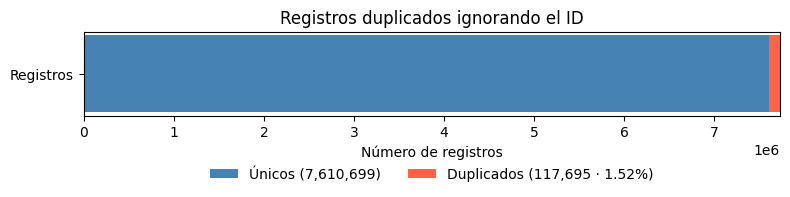

In [12]:
# Proporción de registros únicos y duplicados (ignorando el ID)
fig, ax = plt.subplots(figsize=(8, 2.6))
ax.barh(["Registros"], [n_total - dup_sin_id], color="steelblue", label=f"Únicos ({n_total - dup_sin_id:,})")
ax.barh(["Registros"], [dup_sin_id], left=[n_total - dup_sin_id], color="tomato",
        label=f"Duplicados ({dup_sin_id:,} · {dup_sin_id / n_total:.2%})")
ax.set_xlim(0, n_total)
ax.set_xlabel("Número de registros")
ax.set_title("Registros duplicados ignorando el ID")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.45), ncol=2, frameon=False)
plt.tight_layout()
plt.show()

> **Análisis**
>
> La barra muestra que los duplicados son una fracción pequeña del total. Aun así, en números absolutos son más de cien mil registros, suficiente para alterar los conteos por estado o por fecha del dashboard. Por eso se eliminan en la limpieza.

### 3. Columnas constantes y variables categóricas

Una columna con un solo valor no aporta información al análisis. También se revisan las categorías de las variables de texto para detectar valores escritos de formas distintas.

In [13]:
cardinalidad = df.agg(*[F.approx_count_distinct(F.col(c)).alias(c) for c in df.columns]).collect()[0].asDict()
card_pdf = (pd.DataFrame({"columna": list(cardinalidad.keys()), "valores_distintos": list(cardinalidad.values())})
              .sort_values("valores_distintos").reset_index(drop=True))
constantes = card_pdf.loc[card_pdf["valores_distintos"] <= 1, "columna"].tolist()
print("Columnas con un solo valor:", constantes)
display(card_pdf)

for c in ["Source", "Severity", "Timezone", "Sunrise_Sunset", "Wind_Direction"]:
    print(f"\n=== {c} ===")
    df.groupBy(c).count().orderBy(F.desc("count")).show(30, truncate=False)

print(f"\n=== Weather_Condition (20 más frecuentes de ~{cardinalidad['Weather_Condition']}) ===")
df.groupBy("Weather_Condition").count().orderBy(F.desc("count")).show(20, truncate=False)

Columnas con un solo valor: ['Country', 'Turning_Loop']


,columna,valores_distintos
0,Country,1
1,Turning_Loop,1
2,Amenity,2
3,Bump,2
4,Civil_Twilight,2
5,Sunrise_Sunset,2
6,Traffic_Signal,2
7,Crossing,2
8,Railway,2
9,Stop,2



=== Source ===
+-------+-------+
|Source |count  |
+-------+-------+
|Source1|4325632|
|Source2|3305373|
|Source3|97389  |
+-------+-------+


=== Severity ===
+--------+-------+
|Severity|count  |
+--------+-------+
|2       |6156981|
|3       |1299337|
|4       |204710 |
|1       |67366  |
+--------+-------+


=== Timezone ===
+-----------+-------+
|Timezone   |count  |
+-----------+-------+
|US/Eastern |3580167|
|US/Pacific |2062984|
|US/Central |1645616|
|US/Mountain|431819 |
|NULL       |7808   |
+-----------+-------+


=== Sunrise_Sunset ===
+--------------+-------+
|Sunrise_Sunset|count  |
+--------------+-------+
|Day           |5334553|
|Night         |2370595|
|NULL          |23246  |
+--------------+-------+


=== Wind_Direction ===
+--------------+------+
|Wind_Direction|count |
+--------------+------+
|CALM          |961624|
|S             |419989|
|SSW           |384840|
|W             |383913|
|WNW           |378781|
|NW            |369352|
|Calm          |368557|
|SW  

> **Análisis**
>
> - **Country** (siempre "US") y **Turning_Loop** (siempre False) tienen un solo valor, así que no aportan información y se eliminan en la limpieza.
> - Hay **tres fuentes** de datos: Source1 (56 %), Source2 (43 %) y Source3 (1 %).
> - **Severity está muy desbalanceada**: el nivel 2 concentra el 79.7 % de los registros, el nivel 3 el 16.8 %, el nivel 4 el 2.6 % y el nivel 1 apenas el 0.9 %. Este desbalance es clave para el modelo de la sección 8.
> - **Wind_Direction** tiene categorías que significan lo mismo escritas de distinta forma: CALM y Calm, VAR y Variable, North y N, South y S, etc. Si no se unifican, se contarían como direcciones distintas.
> - **Weather_Condition** tiene unas 150 categorías. Las más frecuentes son Fair (33 %), Mostly Cloudy, Cloudy y Clear. Fair y Clear describen prácticamente la misma condición (cielo despejado), solo que se reportan con distinta etiqueta según la estación.
> - Timezone y Sunrise_Sunset tienen pocos nulos (7,808 y 23,246), que se tratan en la limpieza.

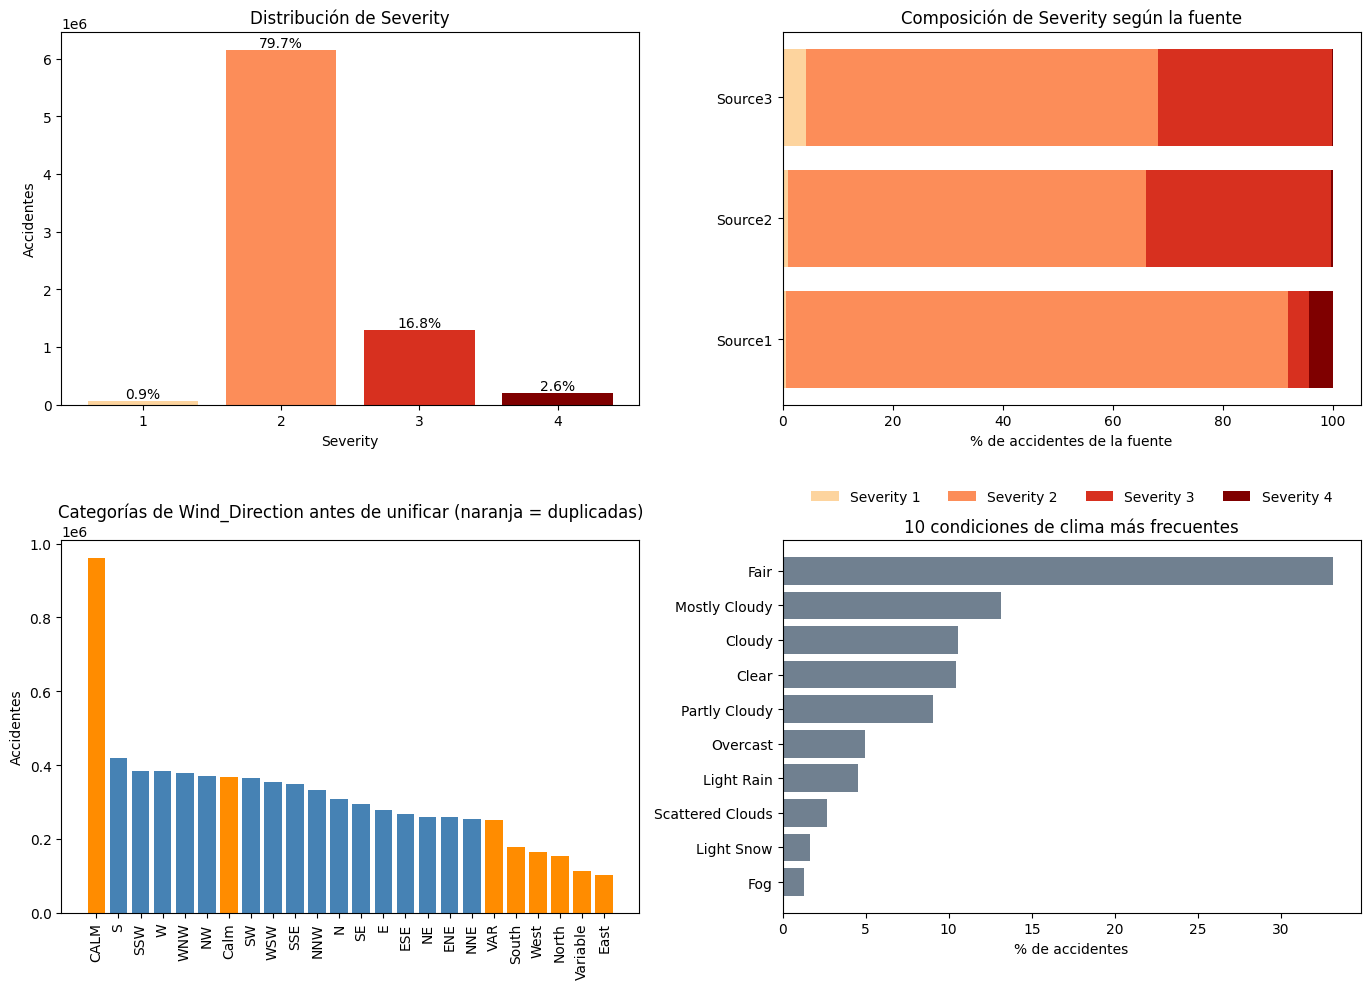

In [14]:
import numpy as np

sev_pdf = df.groupBy("Severity").count().toPandas().sort_values("Severity")
src_sev_pdf = df.groupBy("Source", "Severity").count().toPandas()
viento_pdf = (df.groupBy("Wind_Direction").count().toPandas()
                .dropna().sort_values("count", ascending=False))
clima_pdf = df.groupBy("Weather_Condition").count().toPandas().dropna().nlargest(10, "count")

colores_sev = {1: "#fdd49e", 2: "#fc8d59", 3: "#d7301f", 4: "#7f0000"}
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Distribución de Severity
ax = axes[0, 0]
barras = ax.bar(sev_pdf["Severity"].astype(str), sev_pdf["count"],
                color=[colores_sev[s] for s in sev_pdf["Severity"]])
for b, v in zip(barras, sev_pdf["count"]):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v / n_total:.1%}", ha="center", va="bottom")
ax.set_title("Distribución de Severity")
ax.set_xlabel("Severity")
ax.set_ylabel("Accidentes")

# Severity por fuente (100 %)
ax = axes[0, 1]
tabla = src_sev_pdf.pivot(index="Source", columns="Severity", values="count").fillna(0)
tabla = tabla.div(tabla.sum(axis=1), axis=0) * 100
izquierda = np.zeros(len(tabla))
for s in sorted(tabla.columns):
    ax.barh(tabla.index, tabla[s], left=izquierda, color=colores_sev[s], label=f"Severity {s}")
    izquierda += tabla[s].values
ax.set_xlabel("% de accidentes de la fuente")
ax.set_title("Composición de Severity según la fuente")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.3), ncol=4, frameon=False)

# Categorías de Wind_Direction (en naranja las que se unifican en la limpieza)
ax = axes[1, 0]
a_unificar = {"CALM", "Calm", "VAR", "Variable", "North", "South", "East", "West"}
ax.bar(viento_pdf["Wind_Direction"], viento_pdf["count"],
       color=["darkorange" if w in a_unificar else "steelblue" for w in viento_pdf["Wind_Direction"]])
ax.tick_params(axis="x", rotation=90)
ax.set_title("Categorías de Wind_Direction antes de unificar (naranja = duplicadas)")
ax.set_ylabel("Accidentes")

# 10 condiciones de clima más frecuentes
ax = axes[1, 1]
ax.barh(clima_pdf["Weather_Condition"], clima_pdf["count"] / n_total * 100, color="slategray")
ax.invert_yaxis()
ax.set_xlabel("% de accidentes")
ax.set_title("10 condiciones de clima más frecuentes")

plt.tight_layout()
plt.show()

> **Análisis**
>
> - **Distribución de Severity:** la barra del nivel 2 domina la gráfica. Un modelo que siempre predijera "2" acertaría cerca del 80 % de las veces sin aprender nada, por eso en la sección 8 se usan pesos por clase y métricas por clase, no solo el accuracy.
> - **Severity según la fuente:** permite comparar cómo reparte la severidad cada proveedor. Las diferencias entre fuentes indican que la severidad depende en parte de quién reporta el accidente y no solo de sus condiciones, algo a considerar al interpretar el modelo.
> - **Wind_Direction:** las barras naranjas muestran el problema de categorías duplicadas. CALM (961,624) y Calm (368,557) son la misma condición, igual que VAR y Variable o North y N. Juntas, las formas de "Calm" forman la categoría más grande.
> - **Clima:** casi todos los accidentes ocurren con buen tiempo (Fair, Clear, nublado). Esto no significa que el buen tiempo cause accidentes, sino que es la condición más común: para evaluar el efecto del clima conviene comparar proporciones de accidentes graves, como se hace en la sección 6.1.

### 4. Estadísticas descriptivas y valores fuera de rango

In [15]:
cols_num = [f.name for f in df.schema.fields
            if isinstance(f.dataType, (T.DoubleType, T.FloatType, T.IntegerType, T.LongType))]
resumen = df.select(cols_num).summary("count", "mean", "stddev", "min", "25%", "50%", "75%", "max")
display(resumen.toPandas().set_index("summary").T)

summary,count,mean,stddev,min,25%,50%,75%,max
Severity,7728394,2.212384487643875,0.4875313339360398,1,2,2,2,4
Start_Lat,7728394,36.20119454946952,5.076079113874013,24.5548,33.399153000000005,35.823883,40.084809,49.002201
Start_Lng,7728394,-94.70254538794683,17.39175625334916,-124.623833,-117.21984,-87.76815,-80.353933,-67.113167
End_Lat,4325632,36.26182889161967,5.272904539384689,24.566013,33.462079,36.1833,40.178219,49.075
End_Lng,4325632,-95.72557026006884,18.10792763629359,-124.545748,-117.75501,-88.028149,-80.247326,-67.10924200000001
Distance(mi),7728394,0.5618422831523706,1.7768106031970923,0.0,0.0,0.03,0.464,441.75
Temperature(F),7564541,61.66328580940991,19.013653291093142,-89.0,49.0,64.0,76.0,207.0
Wind_Chill(F),5729375,58.25104839533092,22.3898317496207,-89.0,43.0,62.0,75.0,207.0
Humidity(%),7554250,64.83104146672403,22.820967660113475,1.0,48.0,67.0,84.0,100.0
Pressure(in),7587715,29.538985607656194,1.00618980914562,0.0,29.37,29.86,30.03,58.63


> **Análisis**
>
> Las estadísticas descriptivas revelan valores imposibles en casi todas las variables de clima:
>
> - **Temperatura** de -89 °F y de 207 °F, cuando su rango intercuartílico va de 49 a 76 °F.
> - **Presión** de 0 y de 58.63 inHg, cuando el 50 % central está entre 29.37 y 30.03.
> - **Velocidad del viento** de 1,087 mph y **visibilidad** de 140 millas.
> - **Precipitación** de 36.47 pulgadas en una hora.
>
> También destacan dos distribuciones peculiares: la **visibilidad** tiene sus tres cuartiles en 10 millas (las estaciones reportan "10 o más" como 10) y la **precipitación** tiene sus cuartiles en 0, porque la mayoría de los accidentes ocurre sin lluvia. La **distancia** afectada es muy pequeña en general (mediana de 0.03 millas), pero llega hasta 441 millas, lo que indica una distribución muy sesgada a la derecha.

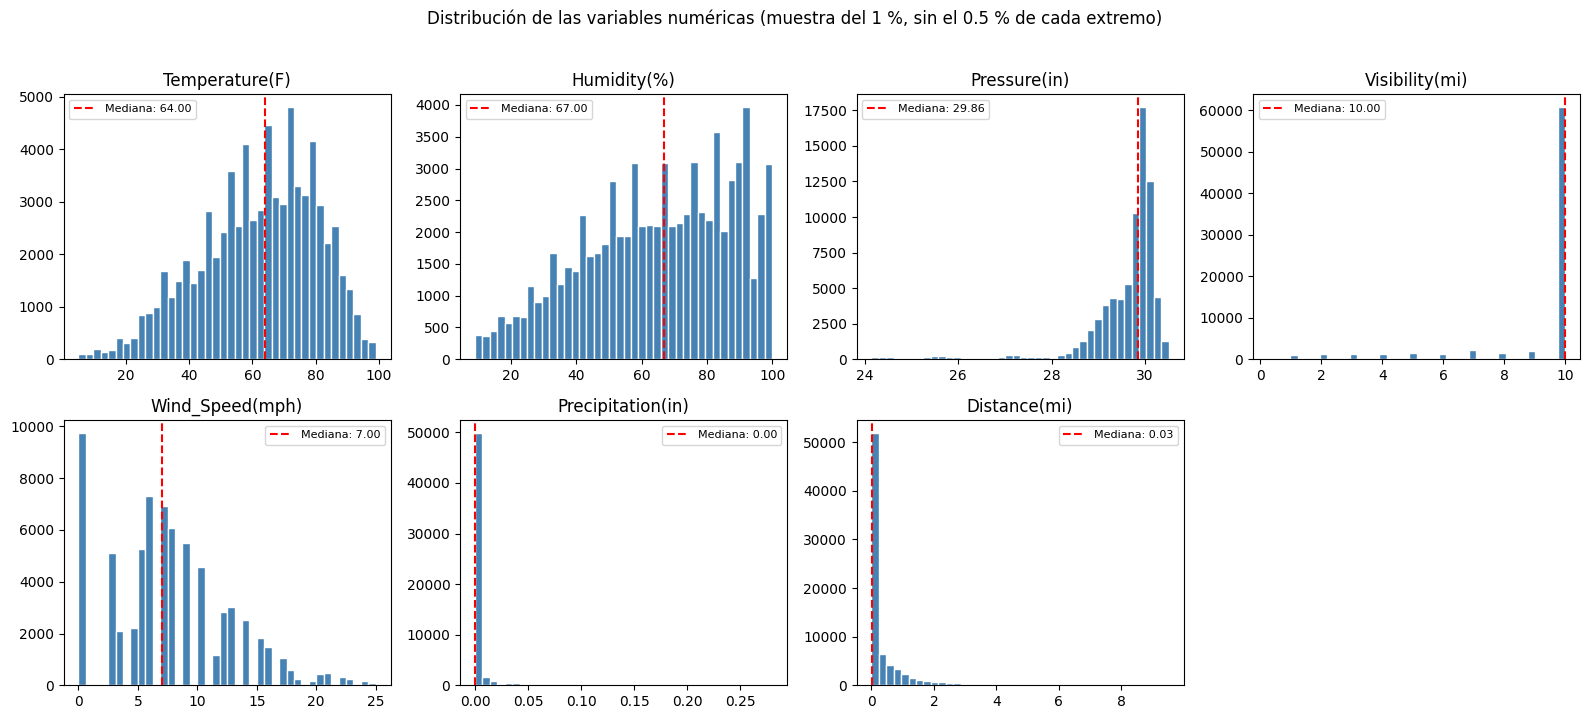

In [16]:
# Histogramas sobre una muestra aleatoria del 1 % (~77 mil registros) para ver la forma de cada distribución
cols_hist = ["Temperature(F)", "Humidity(%)", "Pressure(in)", "Visibility(mi)",
             "Wind_Speed(mph)", "Precipitation(in)", "Distance(mi)"]
muestra_num = df.select(cols_hist).sample(fraction=0.01, seed=42).toPandas()

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.flat, cols_hist):
    serie = muestra_num[c].dropna()
    lim_inf, lim_sup = serie.quantile([0.005, 0.995])   # se recortan los extremos solo para graficar
    ax.hist(serie[(serie >= lim_inf) & (serie <= lim_sup)], bins=40, color="steelblue", edgecolor="white")
    ax.axvline(serie.median(), color="red", linestyle="--", label=f"Mediana: {serie.median():.2f}")
    ax.set_title(c)
    ax.legend(fontsize=8)
axes.flat[-1].axis("off")
fig.suptitle("Distribución de las variables numéricas (muestra del 1 %, sin el 0.5 % de cada extremo)", y=1.02)
plt.tight_layout()
plt.show()

> **Análisis**
>
> Los histogramas confirman lo que sugerían las estadísticas:
>
> - **Temperatura** y **humedad** tienen distribuciones amplias y relativamente simétricas, que reflejan la variedad de climas de Estados Unidos a lo largo del año.
> - **Presión** se concentra cerca de 30 inHg, con una cola hacia valores bajos. Esa cola corresponde a ciudades a mayor altitud, donde la presión de la estación es naturalmente menor.
> - **Visibilidad** y **precipitación** tienen casi todos sus valores en un solo punto (10 millas y 0 pulgadas). Son variables muy concentradas, con pocos casos de mal tiempo.
> - **Velocidad del viento** y **distancia** tienen sesgo a la derecha: la mayoría de los valores son bajos y unos pocos son muy altos.
>
> Como estas variables no siguen una distribución normal, para imputar faltantes se usa la **mediana** y no la media, ya que la mediana no se ve afectada por los valores extremos.

Se definen reglas de validez para detectar valores físicamente imposibles o inconsistentes. Los límites son amplios a propósito: la presión del dataset es la de la estación (en ciudades altas como Denver ronda 24 inHg) y la visibilidad puede ser 0 en niebla, así que solo se marcan valores que no pueden ser reales.

In [17]:
duracion_seg = F.unix_timestamp("End_Time") - F.unix_timestamp("Start_Time")

# Cada condición marca un registro como inconsistente
reglas = {
    "End_Time anterior o igual a Start_Time": F.col("End_Time") <= F.col("Start_Time"),
    "Duración mayor a 30 días":               duracion_seg > 30 * 24 * 3600,
    "Humedad fuera de 0 a 100 %":             ~F.col("Humidity(%)").between(0, 100),
    "Temperatura fuera de -50 a 130 °F":      ~F.col("Temperature(F)").between(-50, 130),
    "Presión fuera de 18 a 32.5 inHg":        ~F.col("Pressure(in)").between(18, 32.5),
    "Visibilidad fuera de 0 a 100 mi":        ~F.col("Visibility(mi)").between(0, 100),
    "Viento fuera de 0 a 150 mph":            ~F.col("Wind_Speed(mph)").between(0, 150),
    "Precipitación fuera de 0 a 10 in":       ~F.col("Precipitation(in)").between(0, 10),
    "Distancia negativa":                     F.col("Distance(mi)") < 0,
    "Coordenadas fuera de EE. UU.":           ~(F.col("Start_Lat").between(18, 72) & F.col("Start_Lng").between(-180, -60)),
}

conteos = df.agg(*[F.sum(F.when(cond, 1).otherwise(0)).alias(f"r{i}")
                   for i, cond in enumerate(reglas.values())]).collect()[0]
reglas_pdf = pd.DataFrame({"regla": list(reglas.keys()), "registros": list(conteos)})
reglas_pdf["porcentaje"] = (reglas_pdf["registros"] / n_total * 100).round(4)
display(reglas_pdf)

,regla,registros,porcentaje
0,End_Time anterior o igual a Start_Time,0,0.0000
1,Duración mayor a 30 días,5477,0.0709
2,Humedad fuera de 0 a 100 %,0,0.0000
3,Temperatura fuera de -50 a 130 °F,66,0.0009
4,Presión fuera de 18 a 32.5 inHg,128,0.0017
5,Visibilidad fuera de 0 a 100 mi,15,0.0002
6,Viento fuera de 0 a 150 mph,51,0.0007
7,Precipitación fuera de 0 a 10 in,60,0.0008
8,Distancia negativa,0,0.0000
9,Coordenadas fuera de EE. UU.,0,0.0000


> **Análisis**
>
> Las reglas de validez marcan muy pocos registros. La más frecuente es **"Duración mayor a 30 días" (5,477 registros, 0.07 %)**: accidentes cuyo registro nunca se cerró correctamente y que aparentan durar semanas o meses. Los demás casos son errores puntuales de medición (66 temperaturas, 128 presiones, 51 velocidades de viento y 60 precipitaciones imposibles).
>
> No hay fechas de fin anteriores al inicio, humedades fuera de rango, distancias negativas ni coordenadas fuera de Estados Unidos, lo que indica que esas columnas ya venían bien validadas desde la fuente.

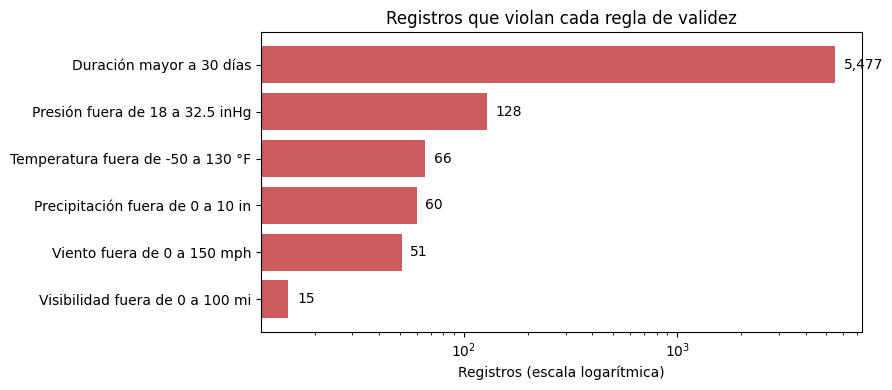

In [18]:
# Registros que violan cada regla (escala logarítmica para ver también las reglas con pocos casos)
violadas = reglas_pdf[reglas_pdf["registros"] > 0].sort_values("registros")
fig, ax = plt.subplots(figsize=(9, 4))
barras = ax.barh(violadas["regla"], violadas["registros"], color="indianred")
for b, v in zip(barras, violadas["registros"]):
    ax.text(v * 1.1, b.get_y() + b.get_height() / 2, f"{v:,}", va="center")
ax.set_xscale("log")
ax.set_xlabel("Registros (escala logarítmica)")
ax.set_title("Registros que violan cada regla de validez")
plt.tight_layout()
plt.show()

> **Análisis**
>
> La escala logarítmica permite ver juntas reglas con miles de casos y reglas con unas decenas. La duración excesiva domina por casi dos órdenes de magnitud, pero aun sumando todas las reglas los registros inválidos no llegan al 0.1 % del dataset, así que eliminarlos no afecta la representatividad de los datos.

Además se cuentan los valores atípicos estadísticos con el criterio del rango intercuartílico (IQR). Estos **no se eliminan**: un accidente con visibilidad 0 o mucha lluvia es raro pero real, y justo esos casos pueden ser los más relevantes para el análisis.

In [19]:
cols_iqr = ["Distance(mi)", "Temperature(F)", "Humidity(%)", "Pressure(in)",
            "Visibility(mi)", "Wind_Speed(mph)", "Precipitation(in)"]
cuartiles = df.approxQuantile(cols_iqr, [0.25, 0.75], 0.001)

limites = {}
for c, (q1, q3) in zip(cols_iqr, cuartiles):
    iqr = q3 - q1
    limites[c] = (q1 - 1.5 * iqr, q3 + 1.5 * iqr)

atipicos = df.agg(*[F.sum(F.when((F.col(c) < li) | (F.col(c) > ls), 1).otherwise(0)).alias(f"a{i}")
                    for i, (c, (li, ls)) in enumerate(limites.items())]).collect()[0]

iqr_pdf = pd.DataFrame({
    "columna": cols_iqr,
    "límite_inf": [round(l[0], 2) for l in limites.values()],
    "límite_sup": [round(l[1], 2) for l in limites.values()],
    "atípicos": list(atipicos),
})
iqr_pdf["porcentaje"] = (iqr_pdf["atípicos"] / n_total * 100).round(2)
display(iqr_pdf)

,columna,límite_inf,límite_sup,atípicos,porcentaje
0,Distance(mi),-0.70,1.16,963606,12.47
1,Temperature(F),8.50,116.50,50515,0.65
2,Humidity(%),-6.00,138.00,0,0.00
3,Pressure(in),28.38,31.02,443383,5.74
4,Visibility(mi),10.00,10.00,1481065,19.16
5,Wind_Speed(mph),-4.10,19.10,210603,2.73
6,Precipitation(in),0.00,0.00,533090,6.90


> **Análisis**
>
> El criterio IQR marca muchos más registros que las reglas de validez, pero en varias columnas el resultado no es confiable:
>
> - **Visibility (19.2 %)** y **Precipitation (6.9 %)** tienen el primer y el tercer cuartil en el mismo valor (10 y 0), así que el IQR es cero. Con un IQR de cero, **cualquier** valor distinto de 10 millas o de 0 pulgadas cuenta como atípico, incluso un día de lluvia ligera.
> - **Distance (12.5 %)** tiene una distribución muy sesgada, así que el IQR marca como atípicos todos los accidentes que afectan más de 1.16 millas de vía, aunque sean casos reales.
> - **Pressure (5.7 %)** marca sobre todo a las ciudades a gran altitud.
>
> Por eso los atípicos estadísticos **no se eliminan**: son condiciones poco frecuentes pero reales (lluvia, niebla, accidentes extensos) y justamente pueden ser los casos más relevantes para analizar la severidad.

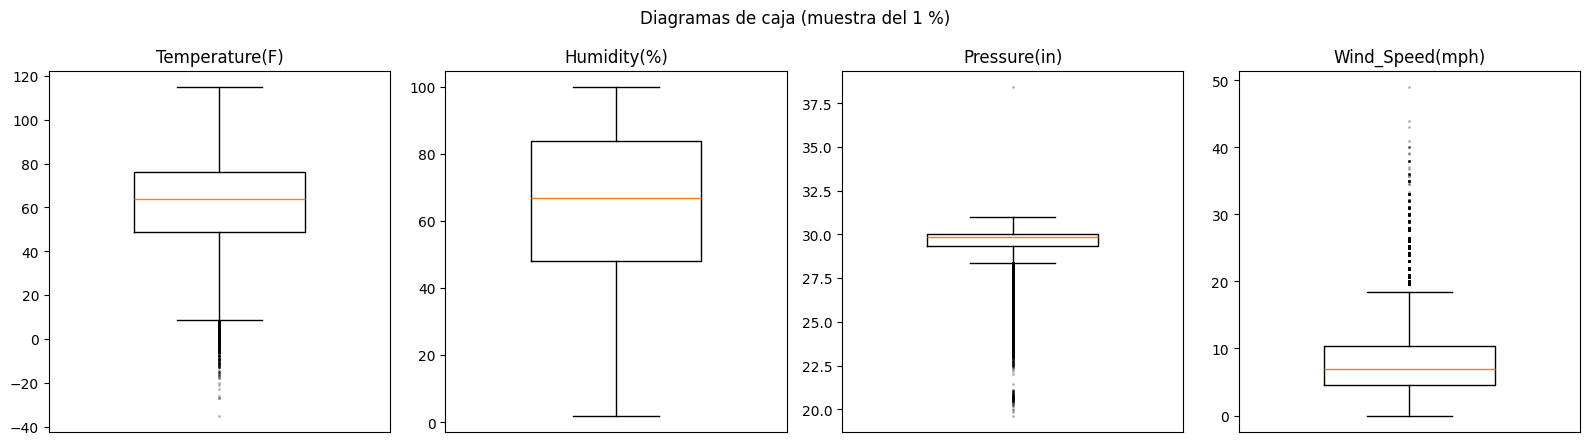

In [20]:
# Diagramas de caja con la muestra del 1 %: los puntos fuera de los bigotes son los atípicos por IQR
cols_caja = ["Temperature(F)", "Humidity(%)", "Pressure(in)", "Wind_Speed(mph)"]
fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
for ax, c in zip(axes, cols_caja):
    ax.boxplot(muestra_num[c].dropna(), vert=True, widths=0.5,
               flierprops={"marker": ".", "markersize": 2, "alpha": 0.3})
    ax.set_title(c)
    ax.set_xticks([])
fig.suptitle("Diagramas de caja (muestra del 1 %)")
plt.tight_layout()
plt.show()

> **Análisis**
>
> En los diagramas de caja, la caja representa el 50 % central de los datos y los puntos fuera de los bigotes son los atípicos por IQR. Se observa que la mayoría de los atípicos forman una nube continua pegada a los bigotes (por ejemplo, los días de mucho viento o las ciudades a gran altitud) y no puntos aislados. Esto refuerza la decisión de conservarlos: forman parte de la variabilidad real del clima y no son errores. Los valores realmente imposibles ya se identificaron con las reglas de validez.

### 5. Limpieza

Criterios aplicados, en este orden:

1. **Estandarizar texto:** quitar espacios sobrantes, convertir cadenas vacías a nulo, unificar las categorías de Wind_Direction (por ejemplo CALM y Calm, VAR y Variable, North y N) y recortar Zipcode a 5 dígitos.
2. **Eliminar duplicados:** registros idénticos en todas las columnas excepto el ID.
3. **Eliminar registros inválidos:** los que violan alguna de las reglas de validez de la sección 4.
4. **Eliminar columnas:** las que tienen más de 40 % de valores faltantes y las que tienen un solo valor.
5. **Valores faltantes restantes:**
   - Columnas con hasta 1 % de faltantes: se eliminan esas filas (son pocas y no sesgan el dataset).
   - Columnas con entre 1 % y 40 %: se imputan. Precipitation se llena con 0, porque la falta de reporte casi siempre significa que no llovió. Wind_Chill se llena con la temperatura, porque la sensación térmica solo difiere de ella con frío y viento. Weather_Timestamp se llena con Start_Time. El resto de las numéricas se llena con la mediana, por ser robusta a atípicos, y las de texto con "Unknown".
6. **Nueva variable:** Duration_min, la duración del accidente en minutos.
7. **Deduplicar otra vez:** la imputación puede volver idénticos registros que antes solo diferían en un valor nulo, así que al final se repite la eliminación de duplicados.

In [21]:
# Liberar la caché de una ejecución anterior de esta celda, si existe
try:
    dfc.unpersist()
except NameError:
    pass

UMBRAL_COLUMNA = 40.0   # % de faltantes a partir del cual se elimina la columna
UMBRAL_FILAS = 1.0      # % de faltantes hasta el cual se eliminan las filas
bitacora = [("Dataset original", n_total, len(df.columns))]

# 5.1 Estandarizar texto
cols_texto = [f.name for f in df.schema.fields if isinstance(f.dataType, T.StringType)]
dfc = df.select([
    F.when(F.trim(F.col(c)) == "", None).otherwise(F.trim(F.col(c))).alias(c) if c in cols_texto else F.col(c)
    for c in df.columns
])
mapa_viento = {"CALM": "Calm", "VAR": "Variable", "North": "N", "South": "S", "East": "E", "West": "W"}
dfc = dfc.replace(mapa_viento, subset=["Wind_Direction"])
dfc = dfc.withColumn("Zipcode", F.substring("Zipcode", 1, 5))

# 5.2 Eliminar duplicados (ignorando el ID)
dfc = dfc.dropDuplicates(cols_sin_id).persist(StorageLevel.MEMORY_AND_DISK)
bitacora.append(("Sin duplicados", dfc.count(), len(dfc.columns)))

# 5.3 Eliminar registros que violan alguna regla de validez (un nulo no cuenta como violación)
invalido = F.lit(False)
for cond in reglas.values():
    invalido = invalido | F.coalesce(cond, F.lit(False))
dfc = dfc.filter(~invalido)
bitacora.append(("Sin registros inválidos", dfc.count(), len(dfc.columns)))

# 5.4 Eliminar columnas con demasiados faltantes o con un solo valor
pct = dict(zip(nulos_pdf["columna"], nulos_pdf["porcentaje"]))
n_nulos = dict(zip(nulos_pdf["columna"], nulos_pdf["nulos"]))
cols_muchos_nulos = [c for c in dfc.columns if pct.get(c, 0) > UMBRAL_COLUMNA]
cols_eliminar = cols_muchos_nulos + [c for c in constantes if c not in cols_muchos_nulos]
dfc = dfc.drop(*cols_eliminar)
print("Columnas eliminadas por faltantes:", cols_muchos_nulos)
print("Columnas eliminadas por ser constantes:", [c for c in constantes if c not in cols_muchos_nulos])
bitacora.append(("Sin columnas descartadas", bitacora[-1][1], len(dfc.columns)))

# 5.5a Eliminar filas en columnas con pocos faltantes
# Se usa el conteo y no el porcentaje redondeado, para no omitir columnas con muy pocos nulos (p. ej. City)
cols_quitar_filas = [c for c in dfc.columns if n_nulos.get(c, 0) > 0 and pct.get(c, 0) <= UMBRAL_FILAS]
dfc = dfc.dropna(subset=cols_quitar_filas)
print("\nFilas eliminadas por faltantes en:", cols_quitar_filas)
bitacora.append(("Sin filas con pocos faltantes", dfc.count(), len(dfc.columns)))

# 5.5b Imputar columnas con faltantes entre 1 % y 40 %
cols_imputar = [c for c in dfc.columns if UMBRAL_FILAS < pct.get(c, 0) <= UMBRAL_COLUMNA]
tipos_c = dict(dfc.dtypes)
especiales = {"Precipitation(in)", "Wind_Chill(F)", "Weather_Timestamp"}
num_mediana = [c for c in cols_imputar if c not in especiales and tipos_c[c] in ("double", "float", "int", "bigint")]
txt_unknown = [c for c in cols_imputar if tipos_c[c] == "string"]
bool_false = [c for c in cols_imputar if tipos_c[c] == "boolean"]

medianas = dict(zip(num_mediana, [q[0] for q in dfc.approxQuantile(num_mediana, [0.5], 0.001)])) if num_mediana else {}
relleno = {**medianas, **{c: "Unknown" for c in txt_unknown}, **{c: False for c in bool_false}}
if "Precipitation(in)" in cols_imputar:
    relleno["Precipitation(in)"] = 0.0
dfc = dfc.fillna(relleno)
if "Wind_Chill(F)" in cols_imputar:
    dfc = dfc.withColumn("Wind_Chill(F)", F.coalesce("Wind_Chill(F)", "Temperature(F)"))
if "Weather_Timestamp" in cols_imputar:
    dfc = dfc.withColumn("Weather_Timestamp", F.coalesce("Weather_Timestamp", "Start_Time"))

print("\nImputación aplicada:")
for c in cols_imputar:
    if c in relleno:
        print(f"  {c}: {relleno[c]}")
    elif c == "Wind_Chill(F)":
        print(f"  {c}: valor de Temperature(F)")
    elif c == "Weather_Timestamp":
        print(f"  {c}: valor de Start_Time")

# 5.6 Duración del accidente en minutos
dfc = dfc.withColumn("Duration_min", F.round(duracion_seg / 60, 2))

dfc = dfc.persist(StorageLevel.MEMORY_AND_DISK)
n_limpio = dfc.count()
bitacora.append(("Dataset limpio (+ Duration_min)", n_limpio, len(dfc.columns)))

bitacora_pdf = pd.DataFrame(bitacora, columns=["paso", "registros", "columnas"])
bitacora_pdf["registros_eliminados"] = (bitacora_pdf["registros"].shift(1) - bitacora_pdf["registros"]).fillna(0).astype(int)
print(f"\nSe conservó el {n_limpio / n_total:.2%} de los registros originales")
display(bitacora_pdf)

Columnas eliminadas por faltantes: ['End_Lat', 'End_Lng']
Columnas eliminadas por ser constantes: ['Country', 'Turning_Loop']

Filas eliminadas por faltantes en: ['Description', 'Street', 'City', 'Zipcode', 'Timezone', 'Airport_Code', 'Sunrise_Sunset', 'Civil_Twilight', 'Nautical_Twilight', 'Astronomical_Twilight']

Imputación aplicada:
  Weather_Timestamp: valor de Start_Time
  Temperature(F): 64.0
  Wind_Chill(F): valor de Temperature(F)
  Humidity(%): 67.0
  Pressure(in): 29.86
  Visibility(mi): 10.0
  Wind_Direction: Unknown
  Wind_Speed(mph): 7.0
  Precipitation(in): 0.0
  Weather_Condition: Unknown

Se conservó el 97.73% de los registros originales


,paso,registros,columnas,registros_eliminados
0,Dataset original,7728394,46,0
1,Sin duplicados,7610699,46,117695
2,Sin registros inválidos,7605649,46,5050
3,Sin columnas descartadas,7605649,42,0
4,Sin filas con pocos faltantes,7552860,42,52789
5,Dataset limpio (+ Duration_min),7552860,43,0


> **Análisis**
>
> La limpieza se aplicó en el orden descrito arriba:
>
> - Se eliminaron **End_Lat y End_Lng** por superar el 40 % de faltantes, y **Country y Turning_Loop** por tener un solo valor.
> - Se eliminaron las filas con faltantes en 10 columnas que tenían menos de 1 % de nulos (Description, Street, City, Zipcode, Timezone, Airport_Code y las cuatro de crepúsculo).
> - Se imputaron 10 columnas. Las numéricas se llenaron con su mediana: 64 °F de temperatura, 67 % de humedad, 29.86 inHg de presión, 10 millas de visibilidad y 7 mph de viento. Las de texto se llenaron con "Unknown". En tres casos se usó una regla con sentido físico: la precipitación faltante se llenó con 0, la sensación térmica con la temperatura y la hora del reporte de clima con la hora de inicio del accidente.
>
> Al final de esta etapa se conserva el **97.73 %** de los registros originales.

In [22]:
# 5.7 La imputación puede volver idénticos registros que antes solo diferían en un nulo
#     (por ejemplo, Precipitation NULL contra 0.0), así que se eliminan duplicados otra vez
cols_sin_id_final = [c for c in dfc.columns if c != "ID"]
dfc_final = dfc.dropDuplicates(cols_sin_id_final).persist(StorageLevel.MEMORY_AND_DISK)
n_final = dfc_final.count()
print(f"Duplicados generados por la imputación: {n_limpio - n_final:,}")

dfc.unpersist()
dfc, n_limpio = dfc_final, n_final
bitacora.append(("Sin duplicados tras imputar", n_limpio, len(dfc.columns)))

bitacora_pdf = pd.DataFrame(bitacora, columns=["paso", "registros", "columnas"])
bitacora_pdf["registros_eliminados"] = (bitacora_pdf["registros"].shift(1) - bitacora_pdf["registros"]).fillna(0).astype(int)
print(f"Se conservó el {n_limpio / n_total:.2%} de los registros originales")
display(bitacora_pdf)

Duplicados generados por la imputación: 30
Se conservó el 97.73% de los registros originales


,paso,registros,columnas,registros_eliminados
0,Dataset original,7728394,46,0
1,Sin duplicados,7610699,46,117695
2,Sin registros inválidos,7605649,46,5050
3,Sin columnas descartadas,7605649,42,0
4,Sin filas con pocos faltantes,7552860,42,52789
5,Dataset limpio (+ Duration_min),7552860,43,0
6,Sin duplicados tras imputar,7552830,43,30


> **Análisis**
>
> Después de imputar, 30 registros quedaron idénticos a otros, porque solo se diferenciaban en un valor que antes era nulo. Se eliminan para que el dataset final no tenga duplicados. La bitácora resume cuántos registros salieron en cada paso.

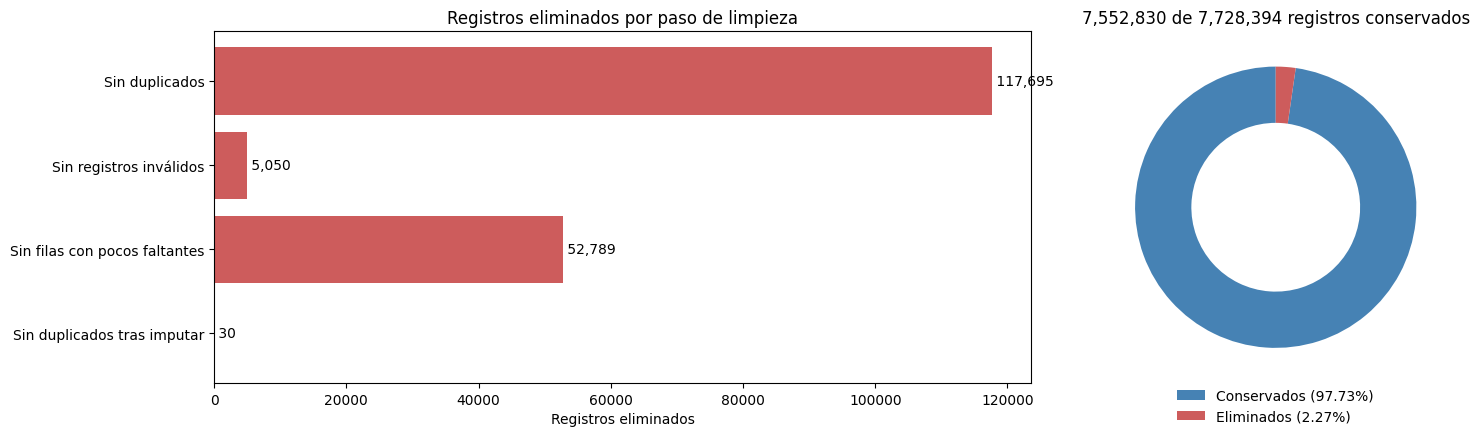

In [23]:
# Registros eliminados en cada paso de la limpieza
pasos = bitacora_pdf[bitacora_pdf["registros_eliminados"] > 0]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [2, 1]})

ax = axes[0]
barras = ax.barh(pasos["paso"], pasos["registros_eliminados"], color="indianred")
for b, v in zip(barras, pasos["registros_eliminados"]):
    ax.text(v, b.get_y() + b.get_height() / 2, f" {v:,}", va="center")
ax.invert_yaxis()
ax.set_xlabel("Registros eliminados")
ax.set_title("Registros eliminados por paso de limpieza")

ax = axes[1]
eliminados = n_total - n_limpio
ax.pie([n_limpio, eliminados], colors=["steelblue", "indianred"], startangle=90,
       wedgeprops={"width": 0.4})
ax.legend([f"Conservados ({n_limpio / n_total:.2%})", f"Eliminados ({eliminados / n_total:.2%})"],
          loc="upper center", bbox_to_anchor=(0.5, 0.02), ncol=1, frameon=False)
ax.set_title(f"{n_limpio:,} de {n_total:,} registros conservados")

plt.tight_layout()
plt.show()

> **Análisis**
>
> En total se eliminaron **175,564 registros (2.27 %)**. La mayor parte corresponde a los **duplicados (117,695)**, seguidos de las filas con faltantes en columnas de ubicación y hora del día (52,789). Los registros con valores imposibles (5,050) y los duplicados que aparecieron después de imputar (30) son una fracción mínima.
>
> La gráfica de dona muestra que la limpieza conserva prácticamente todo el dataset: se corrigieron los problemas de calidad sin perder representatividad.

### 6. Validación del dataset limpio

In [24]:
nulos_final = conteo_nulos(dfc, n_limpio)
dup_final = n_limpio - dfc.dropDuplicates([c for c in dfc.columns if c != "ID"]).count()
inval_final = dfc.filter(F.coalesce(reglas["End_Time anterior o igual a Start_Time"], F.lit(False))).count()

print(f"Registros: {n_limpio:,} | Columnas: {len(dfc.columns)}")
print(f"Columnas con faltantes: {int((nulos_final['nulos'] > 0).sum())}")
print(f"Duplicados (ignorando ID): {dup_final:,}")
print(f"Registros con End_Time <= Start_Time: {inval_final:,}")

print("\nWind_Direction después de unificar:")
dfc.groupBy("Wind_Direction").count().orderBy(F.desc("count")).show(25, truncate=False)

dfc.printSchema()
dfc.show(5, truncate=True)

Registros: 7,552,830 | Columnas: 43
Columnas con faltantes: 0
Duplicados (ignorando ID): 0
Registros con End_Time <= Start_Time: 0

Wind_Direction después de unificar:
+--------------+-------+
|Wind_Direction|count  |
+--------------+-------+
|Calm          |1301335|
|S             |586686 |
|W             |538765 |
|N             |451372 |
|SSW           |378011 |
|E             |374237 |
|WNW           |371278 |
|NW            |361669 |
|Variable      |358917 |
|SW            |358207 |
|WSW           |347568 |
|SSE           |342451 |
|NNW           |326303 |
|SE            |289241 |
|ESE           |263031 |
|NE            |253148 |
|ENE           |252980 |
|NNE           |249898 |
|Unknown       |147733 |
+--------------+-------+

root
 |-- ID: string (nullable = true)
 |-- Source: string (nullable = true)
 |-- Severity: integer (nullable = true)
 |-- Start_Time: timestamp (nullable = true)
 |-- End_Time: timestamp (nullable = true)
 |-- Start_Lat: double (nullable = true)
 |-- Star

> **Análisis**
>
> La validación confirma que el dataset limpio cumple con lo esperado:
>
> - **7,552,830 registros y 43 columnas** (se eliminaron 4 columnas y se agregó Duration_min).
> - **0 columnas con faltantes**, **0 duplicados** y **0 registros con fecha de fin anterior al inicio**.
> - **Wind_Direction** pasó de 25 categorías a 19: las 16 direcciones de la rosa de los vientos más Calm, Variable y Unknown (los faltantes imputados). Calm queda como la categoría más frecuente, con 1.3 millones de registros, después de unir CALM y Calm.
>
> El dataset está listo para el análisis exploratorio, el dashboard y el modelo.

### 6.1 Análisis exploratorio del dataset limpio

Con los datos ya limpios se analiza **cuándo**, **dónde** y **en qué condiciones** ocurren los accidentes, y cómo cambia la proporción de accidentes graves (Severity 3 y 4). Estas gráficas sirven de base para el dashboard y ayudan a interpretar el modelo de la sección 8.

Nota: el archivo llega hasta marzo de 2023, así que ese año está incompleto.

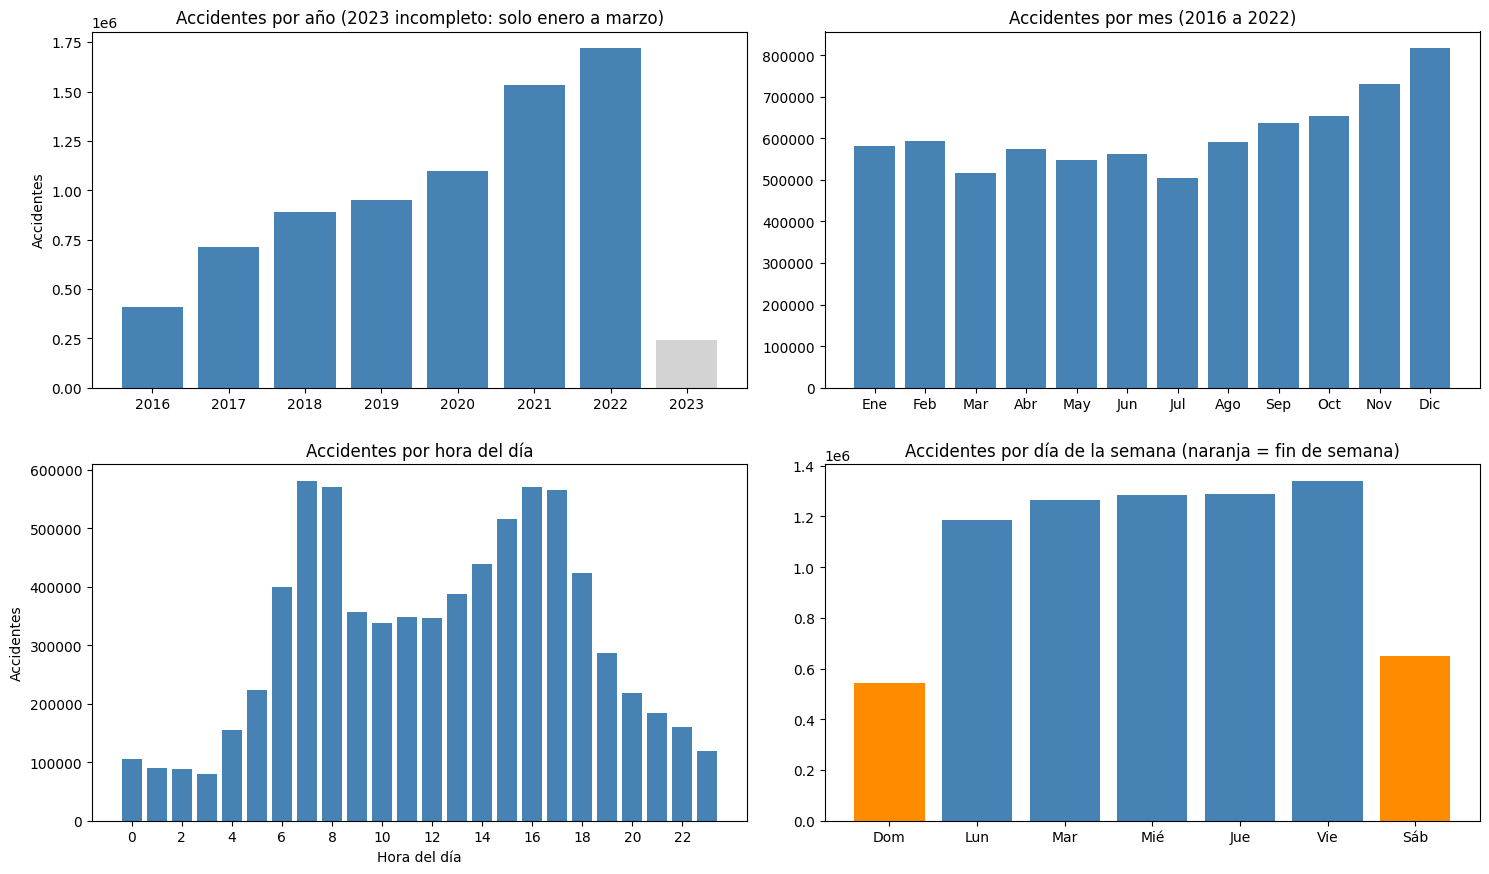

In [25]:
# Una sola agregación con Spark y el resto con pandas: mucho más rápido que agrupar varias veces
tiempo_pdf = (dfc
    .groupBy(F.year("Start_Time").alias("anio"), F.month("Start_Time").alias("mes"),
             F.hour("Start_Time").alias("hora"), F.dayofweek("Start_Time").alias("dia"))
    .count().toPandas())

dias = ["Dom", "Lun", "Mar", "Mié", "Jue", "Vie", "Sáb"]
meses = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]

fig, axes = plt.subplots(2, 2, figsize=(15, 9))

por_anio = tiempo_pdf.groupby("anio")["count"].sum()
ax = axes[0, 0]
ax.bar(por_anio.index.astype(str), por_anio.values,
       color=["lightgray" if a == 2023 else "steelblue" for a in por_anio.index])
ax.set_title("Accidentes por año (2023 incompleto: solo enero a marzo)")
ax.set_ylabel("Accidentes")

por_mes = tiempo_pdf[tiempo_pdf["anio"] < 2023].groupby("mes")["count"].sum()
ax = axes[0, 1]
ax.bar([meses[m - 1] for m in por_mes.index], por_mes.values, color="steelblue")
ax.set_title("Accidentes por mes (2016 a 2022)")

por_hora = tiempo_pdf.groupby("hora")["count"].sum()
ax = axes[1, 0]
ax.bar(por_hora.index, por_hora.values, color="steelblue")
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("Hora del día")
ax.set_ylabel("Accidentes")
ax.set_title("Accidentes por hora del día")

por_dia = tiempo_pdf.groupby("dia")["count"].sum()
ax = axes[1, 1]
ax.bar([dias[d - 1] for d in por_dia.index], por_dia.values,
       color=["darkorange" if d in (1, 7) else "steelblue" for d in por_dia.index])
ax.set_title("Accidentes por día de la semana (naranja = fin de semana)")

plt.tight_layout()
plt.show()

> **Análisis**
>
> Estas cuatro gráficas describen el comportamiento temporal de los accidentes:
>
> - **Por año:** muestra cómo cambia el volumen de accidentes registrados de 2016 a 2022. Hay que interpretar los cambios con cuidado, porque el número de registros depende también de la cobertura de las fuentes de datos en cada año, no solo de cuántos accidentes ocurrieron. La barra gris de 2023 es baja porque solo incluye tres meses.
> - **Por mes:** permite identificar la estacionalidad, es decir, si hay meses con más accidentes, por ejemplo por clima invernal o por temporadas de vacaciones.
> - **Por hora:** refleja los ritmos de movilidad diaria. Los picos coinciden con las horas en que más personas se desplazan, como la entrada y la salida del trabajo.
> - **Por día de la semana:** compara días laborales contra fines de semana (barras naranjas). Una diferencia marcada entre ambos confirma que el volumen de tráfico laboral es uno de los principales factores del número de accidentes.

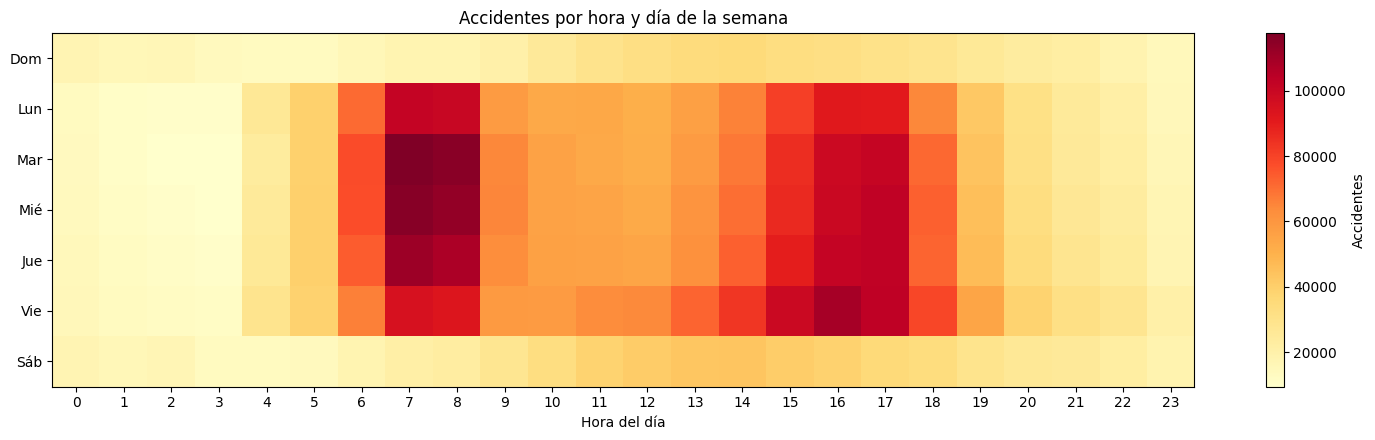

In [26]:
# Mapa de calor: hora del día contra día de la semana
calor = tiempo_pdf.groupby(["dia", "hora"])["count"].sum().unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(15, 4.5))
im = ax.imshow(calor.values, aspect="auto", cmap="YlOrRd")
ax.set_yticks(range(len(calor.index)))
ax.set_yticklabels([dias[d - 1] for d in calor.index])
ax.set_xticks(range(24))
ax.set_xlabel("Hora del día")
ax.set_title("Accidentes por hora y día de la semana")
fig.colorbar(im, ax=ax, label="Accidentes")
plt.tight_layout()
plt.show()

> **Análisis**
>
> El mapa de calor combina las dos gráficas anteriores y muestra **en qué momento exacto de la semana** se concentran los accidentes: las celdas más oscuras son las combinaciones de día y hora con más casos. Permite ver si los picos de las horas de entrada y salida del trabajo ocurren solo entre semana y cómo cambia el patrón en sábado y domingo, cuando no hay horario laboral. Es una de las gráficas propuestas para el dashboard de Tableau.

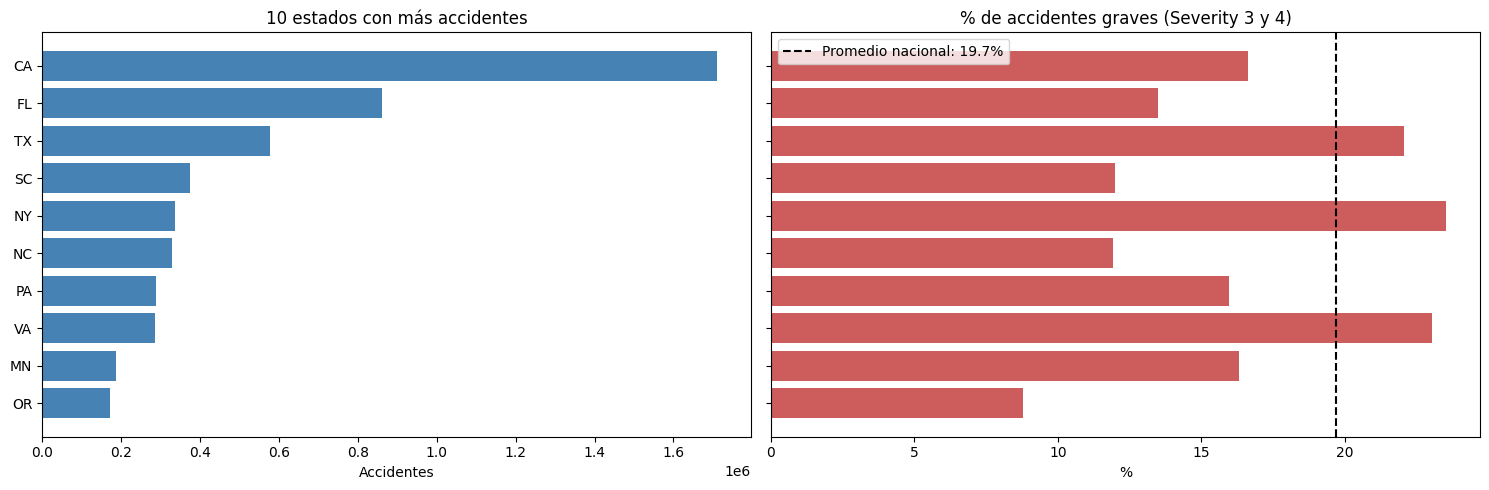

In [27]:
# Estados con más accidentes y proporción de accidentes graves en cada uno
estado_pdf = (dfc.groupBy("State")
                .agg(F.count("*").alias("accidentes"),
                     F.avg((F.col("Severity") >= 3).cast("int")).alias("pct_graves"))
                .toPandas())
top_estados = estado_pdf.nlargest(10, "accidentes").sort_values("accidentes")
pct_nacional = dfc.select(F.avg((F.col("Severity") >= 3).cast("int"))).first()[0]

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
axes[0].barh(top_estados["State"], top_estados["accidentes"], color="steelblue")
axes[0].set_title("10 estados con más accidentes")
axes[0].set_xlabel("Accidentes")

axes[1].barh(top_estados["State"], top_estados["pct_graves"] * 100, color="indianred")
axes[1].axvline(pct_nacional * 100, color="black", linestyle="--",
                label=f"Promedio nacional: {pct_nacional:.1%}")
axes[1].set_title("% de accidentes graves (Severity 3 y 4)")
axes[1].set_xlabel("%")
axes[1].legend()
plt.tight_layout()
plt.show()

> **Análisis**
>
> La comparación lado a lado muestra que **tener más accidentes no implica tener accidentes más graves**. La gráfica de la izquierda refleja principalmente el tamaño de la población y de la red vial de cada estado. La de la derecha compara la proporción de accidentes graves de esos mismos estados contra el promedio nacional (línea punteada): los estados que la rebasan tienen, proporcionalmente, accidentes más severos, aunque no necesariamente más accidentes.
>
> Por eso el mapa del dashboard incluye las dos métricas (número de accidentes y porcentaje de graves).

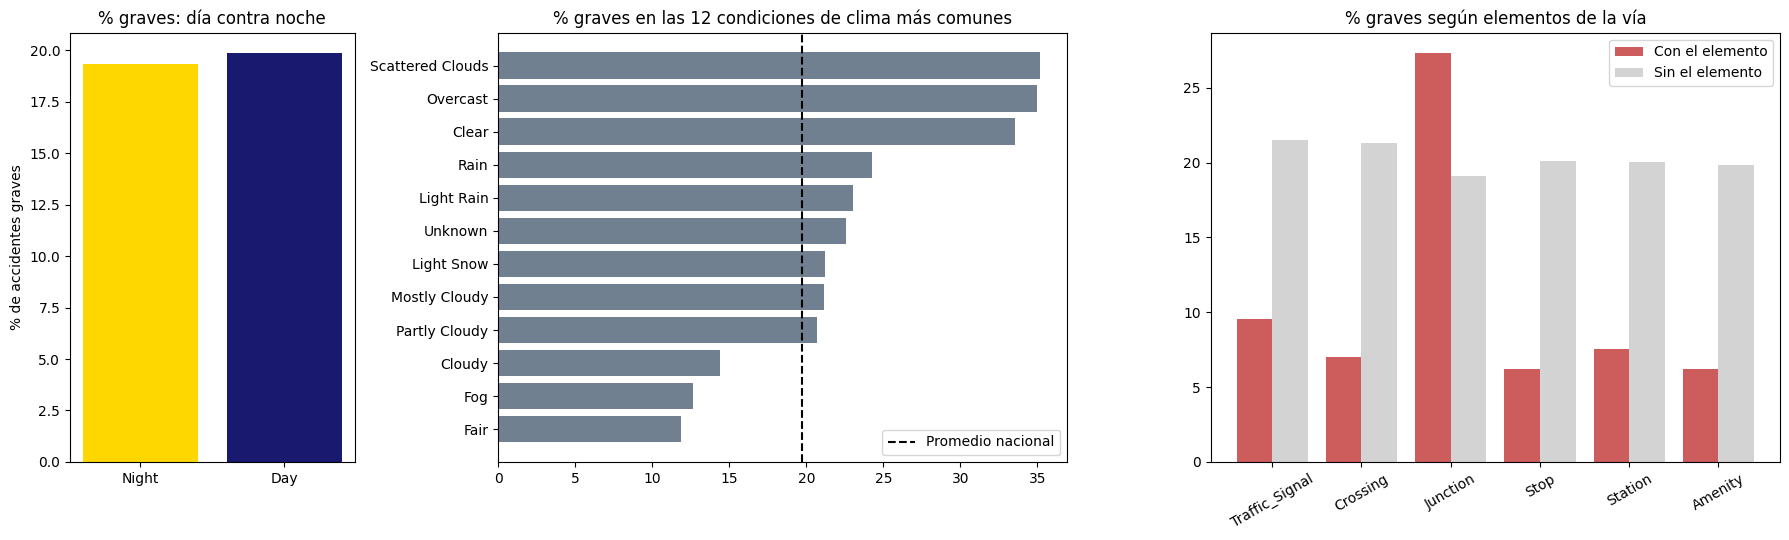

In [28]:
# Proporción de accidentes graves según condiciones del entorno
def pct_graves_por(col, top=None):
    pdf = (dfc.groupBy(col)
             .agg(F.count("*").alias("accidentes"),
                  F.avg((F.col("Severity") >= 3).cast("int")).alias("pct_graves"))
             .toPandas())
    if top:
        pdf = pdf.nlargest(top, "accidentes")
    return pdf.sort_values("pct_graves")

luz_pdf = pct_graves_por("Sunrise_Sunset")
clima_sev_pdf = pct_graves_por("Weather_Condition", top=12)

vias = ["Traffic_Signal", "Crossing", "Junction", "Stop", "Station", "Amenity"]
vias_pdf = (dfc.select([F.avg(F.when(F.col(v), (F.col("Severity") >= 3).cast("int"))).alias(f"{v}_si")
                        for v in vias] +
                       [F.avg(F.when(~F.col(v), (F.col("Severity") >= 3).cast("int"))).alias(f"{v}_no")
                        for v in vias])
              .toPandas().iloc[0])

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), gridspec_kw={"width_ratios": [1, 2, 2]})

axes[0].bar(luz_pdf["Sunrise_Sunset"], luz_pdf["pct_graves"] * 100, color=["gold", "midnightblue"])
axes[0].set_title("% graves: día contra noche")
axes[0].set_ylabel("% de accidentes graves")

axes[1].barh(clima_sev_pdf["Weather_Condition"], clima_sev_pdf["pct_graves"] * 100, color="slategray")
axes[1].axvline(pct_nacional * 100, color="black", linestyle="--", label="Promedio nacional")
axes[1].set_title("% graves en las 12 condiciones de clima más comunes")
axes[1].legend()

x = np.arange(len(vias))
axes[2].bar(x - 0.2, [vias_pdf[f"{v}_si"] * 100 for v in vias], 0.4, label="Con el elemento", color="indianred")
axes[2].bar(x + 0.2, [vias_pdf[f"{v}_no"] * 100 for v in vias], 0.4, label="Sin el elemento", color="lightgray")
axes[2].set_xticks(x)
axes[2].set_xticklabels(vias, rotation=30)
axes[2].set_title("% graves según elementos de la vía")
axes[2].legend()

plt.tight_layout()
plt.show()

> **Análisis**
>
> Estas gráficas comparan la **proporción de accidentes graves** en distintas condiciones, lo que elimina el efecto de que unas condiciones sean más comunes que otras:
>
> - **Día contra noche:** indica si los accidentes nocturnos tienden a ser más severos, por ejemplo por menor visibilidad o mayor velocidad en vías vacías.
> - **Clima:** las condiciones cuya barra rebasa la línea punteada tienen más accidentes graves que el promedio. Esta comparación es la forma correcta de medir el efecto del clima, a diferencia del conteo bruto de la sección 3, donde el buen tiempo dominaba solo por ser la condición más frecuente.
> - **Elementos de la vía:** compara la proporción de graves cuando hay un semáforo, cruce, intersección, alto, estación o servicio cerca contra cuando no lo hay. Los elementos que reducen la velocidad del tráfico (como semáforos y altos) suelen asociarse con accidentes menos severos, mientras que en las vías rápidas sin estos elementos los choques ocurren a mayor velocidad.
>
> Estas relaciones explican por qué las variables de entorno se incluyen como predictoras en el modelo.

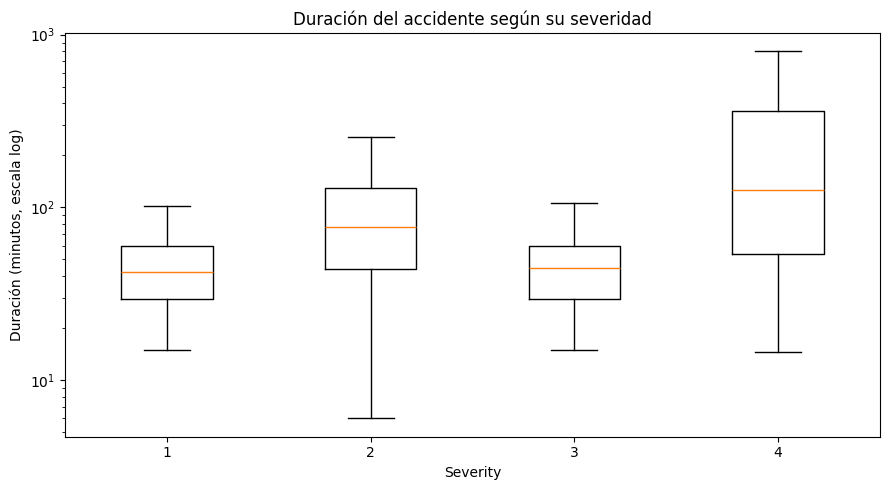

,mediana_minutos
Severity,
1,42.130
2,77.180
3,44.430
4,126.625


In [29]:
# Duración del accidente según su severidad (muestra del 1 %, escala logarítmica)
dur_pdf = dfc.select("Severity", "Duration_min").sample(fraction=0.01, seed=42).toPandas()
fig, ax = plt.subplots(figsize=(9, 5))
ax.boxplot([dur_pdf.loc[dur_pdf["Severity"] == s, "Duration_min"] for s in [1, 2, 3, 4]],
           showfliers=False)
ax.set_xticks([1, 2, 3, 4], ["1", "2", "3", "4"])
ax.set_yscale("log")
ax.set_xlabel("Severity")
ax.set_ylabel("Duración (minutos, escala log)")
ax.set_title("Duración del accidente según su severidad")
plt.tight_layout()
plt.show()
display(dur_pdf.groupby("Severity")["Duration_min"].median().rename("mediana_minutos").to_frame())

> **Análisis**
>
> Severity mide el impacto del accidente en el tráfico, así que se espera que los accidentes más severos interrumpan la circulación por más tiempo. La gráfica y la tabla de medianas permiten comprobar esa relación.
>
> Justamente por esta relación, **Duration_min no se usa como variable predictora** en el modelo: la duración solo se conoce cuando el accidente ya terminó, y usarla para predecir la severidad sería una fuga de información (*data leakage*).

### 7. Guardar el dataset limpio

Se guarda en Parquet, un formato columnar comprimido que ocupa mucho menos que el CSV y que Spark lee mucho más rápido. Las siguientes etapas pueden cargarlo directamente con spark.read.parquet(ruta_salida).

In [30]:
ruta_salida = "/content/drive/MyDrive/BigData_Dataset/US_Accidents_clean.parquet"
dfc.write.mode("overwrite").parquet(ruta_salida)
print("Dataset limpio guardado en:", ruta_salida)

Dataset limpio guardado en: /content/drive/MyDrive/BigData_Dataset/US_Accidents_clean.parquet


> **Análisis**
>
> El dataset limpio se guarda en formato **Parquet** dentro de Google Drive. Parquet almacena los datos por columnas y comprimidos, por lo que ocupa mucho menos espacio que el CSV original y Spark lo lee mucho más rápido. Además conserva el esquema (tipos de cada columna), así que no es necesario volver a inferirlo. Si la sesión de Colab se reinicia, se puede cargar este archivo y continuar desde la sección 8 sin repetir la limpieza.

## 8. Modelo de clasificación con MLlib: Random Forest

Para predecir Severity (1 a 4) se usa **RandomForestClassifier**, un clasificador de la librería MLlib de PySpark. Se eligió por estas razones:

- Admite clasificación multiclase de forma nativa. GBTClassifier, el boosting de MLlib, solo admite dos clases.
- Captura relaciones no lineales entre las variables.
- Acepta pesos por registro (weightCol), lo que permite compensar el desbalance de clases.
- Calcula la importancia de cada variable.

**Variables predictoras:**
- Numéricas: coordenadas y variables de clima (temperatura, sensación térmica, humedad, presión, visibilidad, viento y precipitación).
- Temporales derivadas de Start_Time: hora, día de la semana, mes y año.
- Indicadores booleanos del entorno vial (cruce, semáforo, alto, etc.).
- Categóricas indexadas: Source, State, Timezone, Weather_Condition, Wind_Direction y los cuatro periodos de luz del día.

**Variables excluidas:**
- Por fuga de información: End_Time, Duration_min y Distance(mi) solo se conocen una vez que el accidente terminó, y Severity mide justamente su impacto en el tráfico.
- Por ser identificadores o texto libre: ID y Description.
- Por tener demasiadas categorías para indexarlas con utilidad: Street, City, County, Zipcode y Airport_Code.

In [31]:
# Liberar memoria: ya no se necesita el CSV original en caché
df.unpersist()

# Nombres de columna sin paréntesis ni símbolos, más cómodos para el modelado
renombres = {c: c.replace("(%)", "_pct").replace("(", "_").replace(")", "") for c in dfc.columns}
datos_limpios = dfc.select([F.col(c).alias(renombres[c]) for c in dfc.columns])

# Fijar el dataset limpio en disco local para cortar el linaje y liberar la caché
ruta_tmp = "/content/us_accidents_limpio_tmp.parquet"
datos_limpios.write.mode("overwrite").parquet(ruta_tmp)
dfc.unpersist()

datos = spark.read.parquet(ruta_tmp)
print(f"{datos.count():,} registros | columnas: {datos.columns}")

7,552,830 registros | columnas: ['ID', 'Source', 'Severity', 'Start_Time', 'End_Time', 'Start_Lat', 'Start_Lng', 'Distance_mi', 'Description', 'Street', 'City', 'County', 'State', 'Zipcode', 'Timezone', 'Airport_Code', 'Weather_Timestamp', 'Temperature_F', 'Wind_Chill_F', 'Humidity_pct', 'Pressure_in', 'Visibility_mi', 'Wind_Direction', 'Wind_Speed_mph', 'Precipitation_in', 'Weather_Condition', 'Amenity', 'Bump', 'Crossing', 'Give_Way', 'Junction', 'No_Exit', 'Railway', 'Roundabout', 'Station', 'Stop', 'Traffic_Calming', 'Traffic_Signal', 'Sunrise_Sunset', 'Civil_Twilight', 'Nautical_Twilight', 'Astronomical_Twilight', 'Duration_min']


> **Análisis**
>
> Se libera la memoria del dataset original y se renombran las columnas para quitar paréntesis y símbolos (por ejemplo, `Temperature(F)` pasa a `Temperature_F`), que pueden causar errores en las etapas de MLlib.
>
> El dataset se escribe en disco y se vuelve a leer para **cortar el linaje** de Spark: sin este paso, cada operación del modelo arrastraría todas las transformaciones de la limpieza. La salida confirma que se conservan los 7,552,830 registros.

### 8.1 Preparación de los datos

Los clasificadores de MLlib esperan las clases numeradas desde 0, así que Severity (1 a 4) se transforma en label (0 a 3). Por los recursos de Colab (2 núcleos y 12 GB de RAM) se trabaja con una **muestra estratificada del 5 %** (~375 mil registros), que conserva la proporción de cada clase. La muestra se divide en 80 % para entrenamiento con validación cruzada y 20 % de prueba, que el modelo no ve sino hasta la evaluación final.

Las clases están muy desbalanceadas (Severity 2 es ~80 % de los datos y Severity 1 menos de 1 %). Por eso se asigna a cada registro un **peso inversamente proporcional a la frecuencia de su clase**; así el modelo no aprende a predecir siempre la clase mayoritaria.

In [32]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, VectorAssembler
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

bool_cols = [f.name for f in datos.schema.fields if isinstance(f.dataType, T.BooleanType)]
num_cols = ["Start_Lat", "Start_Lng", "Temperature_F", "Wind_Chill_F", "Humidity_pct", "Pressure_in",
            "Visibility_mi", "Wind_Speed_mph", "Precipitation_in", "hora", "dia_semana", "mes", "anio"]
cat_cols = ["Source", "State", "Timezone", "Weather_Condition", "Wind_Direction",
            "Sunrise_Sunset", "Civil_Twilight", "Nautical_Twilight", "Astronomical_Twilight"]

datos_ml = (datos
    .withColumn("label", (F.col("Severity") - 1).cast("double"))
    .withColumn("hora", F.hour("Start_Time"))
    .withColumn("dia_semana", F.dayofweek("Start_Time"))
    .withColumn("mes", F.month("Start_Time"))
    .withColumn("anio", F.year("Start_Time"))
    .select(["label"] + num_cols + bool_cols + cat_cols))
for c in bool_cols:
    datos_ml = datos_ml.withColumn(c, F.col(c).cast("int"))

# Muestra estratificada: la misma fracción en cada clase conserva su proporción
FRACCION = 0.05
muestra = datos_ml.sampleBy("label", fractions={float(k): FRACCION for k in range(4)}, seed=42)
train, test = muestra.randomSplit([0.8, 0.2], seed=42)

# Pesos balanceados: total / (n_clases * registros_de_la_clase)
conteo = {r["label"]: r["count"] for r in train.groupBy("label").count().collect()}
total_train = sum(conteo.values())
pesos = {k: total_train / (len(conteo) * v) for k, v in conteo.items()}
mapa_pesos = F.create_map([F.lit(x) for kv in pesos.items() for x in kv])
train = train.withColumn("peso", mapa_pesos[F.col("label")]).persist(StorageLevel.MEMORY_AND_DISK)
test = test.persist(StorageLevel.MEMORY_AND_DISK)

n_train, n_test = train.count(), test.count()
resumen_clases = pd.DataFrame({
    "Severity": [int(k) + 1 for k in sorted(conteo)],
    "registros_train": [conteo[k] for k in sorted(conteo)],
    "porcentaje": [round(conteo[k] / total_train * 100, 2) for k in sorted(conteo)],
    "peso": [round(pesos[k], 3) for k in sorted(conteo)],
})
print(f"Entrenamiento: {n_train:,} registros | Prueba: {n_test:,} registros")
display(resumen_clases)

Entrenamiento: 301,842 registros | Prueba: 74,853 registros


,Severity,registros_train,porcentaje,peso
0,1,2650,0.88,28.476
1,2,239712,79.42,0.315
2,3,51730,17.14,1.459
3,4,7750,2.57,9.737


> **Análisis**
>
> La muestra estratificada del 5 % produce **301,842 registros de entrenamiento y 74,853 de prueba**. La tabla confirma que la muestra conserva las proporciones originales de Severity (79.4 % del nivel 2, 0.9 % del nivel 1).
>
> Los pesos compensan ese desbalance. Un registro de **Severity 1 pesa 28.48** y uno de **Severity 2 pesa 0.315**, es decir, para el modelo cada accidente de nivel 1 vale lo mismo que unos 90 accidentes de nivel 2. Así, las cuatro clases tienen la misma importancia total durante el entrenamiento.

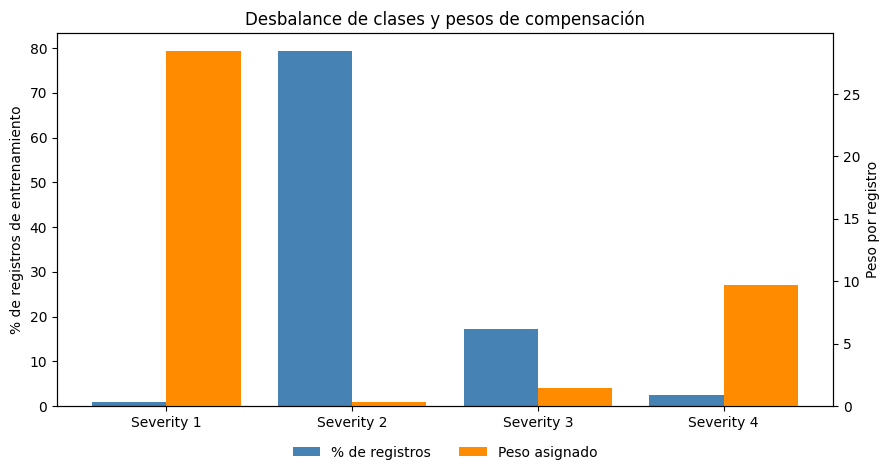

In [33]:
# Proporción de cada clase en el entrenamiento y peso asignado
fig, ax1 = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(resumen_clases))
ax1.bar(x - 0.2, resumen_clases["porcentaje"], 0.4, color="steelblue", label="% de registros")
ax1.set_ylabel("% de registros de entrenamiento")
ax2 = ax1.twinx()
ax2.bar(x + 0.2, resumen_clases["peso"], 0.4, color="darkorange", label="Peso asignado")
ax2.set_ylabel("Peso por registro")
ax1.set_xticks(x)
ax1.set_xticklabels([f"Severity {s}" for s in resumen_clases["Severity"]])
ax1.set_title("Desbalance de clases y pesos de compensación")
fig.legend(loc="lower center", bbox_to_anchor=(0.5, -0.06), ncol=2, frameon=False)
plt.tight_layout()
plt.show()

> **Análisis**
>
> La gráfica muestra que los pesos son el espejo del desbalance: las clases con menos registros (barras azules bajas) reciben los pesos más altos (barras naranjas altas). Así el modelo no puede ignorar las clases minoritarias para maximizar su exactitud.

### 8.2 Pipeline y validación cruzada k-fold

El Pipeline encadena tres etapas: StringIndexer para cada variable categórica, VectorAssembler para juntar todas las variables en un vector y RandomForestClassifier. El Pipeline completo se pasa al CrossValidator de MLlib, de modo que los índices de las categorías se aprenden solo con los datos de entrenamiento de cada fold y no se filtra información del fold de validación.

Con **k = 5**, el conjunto de entrenamiento se divide en 5 partes. Cada combinación de hiperparámetros se entrena 5 veces, cada vez con 4 partes, y se valida con la parte restante. El F1 promedio de los 5 folds decide la mejor combinación, que después se reentrena con todo el conjunto de entrenamiento. Se prueban dos profundidades máximas (10 y 15) con 60 árboles cada una.

Como StringIndexer marca sus columnas como categóricas, Random Forest las trata como categorías y no como números. Para eso necesita que maxBins sea mayor que el número de categorías de la variable más grande (Weather_Condition tiene ~150), por lo que se fija maxBins = 200.

In [34]:
from pyspark.ml.classification import RandomForestClassifier
import time

indexadores_rf = [StringIndexer(inputCol=c, outputCol=f"{c}_idx", handleInvalid="keep") for c in cat_cols]
cols_features = num_cols + bool_cols + [f"{c}_idx" for c in cat_cols]
ensamblador_rf = VectorAssembler(inputCols=cols_features, outputCol="features", handleInvalid="keep")

rf = RandomForestClassifier(
    featuresCol="features",
    labelCol="label",
    weightCol="peso",                   # pesos por clase definidos en 8.1
    numTrees=60,
    maxBins=200,                        # mayor que el número de categorías de Weather_Condition
    featureSubsetStrategy="sqrt",
    subsamplingRate=0.8,
    maxMemoryInMB=512,
    cacheNodeIds=True,                  # acelera el entrenamiento de árboles profundos
    seed=42,
)
pipeline_rf = Pipeline(stages=indexadores_rf + [ensamblador_rf, rf])

evaluador_f1 = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="f1")
grid_rf = ParamGridBuilder().addGrid(rf.maxDepth, [10, 15]).build()
cv_rf = CrossValidator(estimator=pipeline_rf, estimatorParamMaps=grid_rf, evaluator=evaluador_f1,
                       numFolds=5, seed=42, parallelism=1)

inicio = time.time()
modelo_cv_rf = cv_rf.fit(train)
print(f"Validación cruzada terminada en {(time.time() - inicio) / 60:.1f} minutos\n")

resultados_cv_rf = pd.DataFrame({
    "maxDepth": [p[rf.maxDepth] for p in grid_rf],
    "F1_promedio_5_folds": [round(m, 4) for m in modelo_cv_rf.avgMetrics],
    "desviación_estándar": [round(s, 4) for s in modelo_cv_rf.stdMetrics],
})
display(resultados_cv_rf)

Validación cruzada terminada en 69.3 minutos



,maxDepth,F1_promedio_5_folds,desviación_estándar
0,10,0.6686,0.0035
1,15,0.7588,0.0024


> **Análisis**
>
> La validación cruzada de 5 folds tardó 82 minutos y entrenó 10 modelos (2 profundidades por 5 folds), más el reentrenamiento final del mejor.
>
> - Con **profundidad 15** el F1 promedio fue de **0.759**, contra **0.669** con profundidad 10. Los árboles más profundos pueden combinar más variables en cada decisión y capturar relaciones más complejas.
> - La **desviación estándar** entre folds es muy baja (0.002 a 0.004), así que el desempeño casi no depende de qué datos quedaron en cada fold: el modelo es estable.
>
> El CrossValidator selecciona automáticamente la profundidad 15 como mejor modelo.

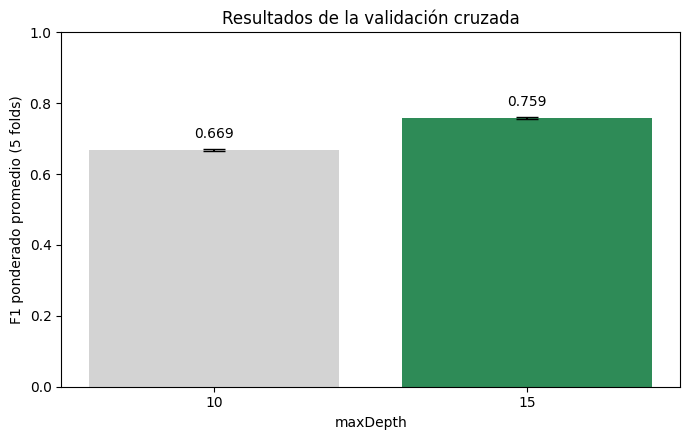

In [35]:
# F1 promedio de cada profundidad, con su desviación estándar entre folds
fig, ax = plt.subplots(figsize=(7, 4.5))
barras = ax.bar(resultados_cv_rf["maxDepth"].astype(str), resultados_cv_rf["F1_promedio_5_folds"],
                yerr=resultados_cv_rf["desviación_estándar"], capsize=8, color=["lightgray", "seagreen"])
for b, v, s in zip(barras, resultados_cv_rf["F1_promedio_5_folds"], resultados_cv_rf["desviación_estándar"]):
    ax.text(b.get_x() + b.get_width() / 2, v + s + 0.03, f"{v:.3f}", ha="center")
ax.set_ylim(0, 1)
ax.set_xlabel("maxDepth")
ax.set_ylabel("F1 ponderado promedio (5 folds)")
ax.set_title("Resultados de la validación cruzada")
plt.tight_layout()
plt.show()

> **Análisis**
>
> Las barras de error (desviación estándar) son tan pequeñas que casi no se distinguen, lo que confirma que la diferencia de 9 puntos entre ambas profundidades es real y no producto de la partición de los datos.

### 8.3 Evaluación con herramientas de PySpark

Toda la evaluación se hace con **MulticlassClassificationEvaluator** de pyspark.ml.evaluation y con operaciones de DataFrames de Spark:

- **Métricas globales:** accuracy, F1, precisión y recall ponderados, y log loss (que mide qué tan bien calibradas están las probabilidades).
- **Métricas por clase:** con el parámetro metricLabel se obtienen precisión, recall, F1 y tasa de falsos positivos de cada nivel de Severity. El F1 macro es el promedio simple de los F1 por clase.
- **Matriz de confusión:** se construye con groupBy y pivot sobre las predicciones.

In [36]:
ev = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", probabilityCol="probability")

def evaluar(predicciones):
    """Métricas globales y por clase calculadas con MulticlassClassificationEvaluator."""
    globales = {nombre: ev.evaluate(predicciones, {ev.metricName: m}) for nombre, m in [
        ("Accuracy", "accuracy"), ("F1 ponderado", "f1"), ("Precisión ponderada", "weightedPrecision"),
        ("Recall ponderado", "weightedRecall"), ("Log loss", "logLoss")]}
    por_clase = []
    for k in range(4):
        fila = {"Severity": k + 1}
        for nombre, m in [("precisión", "precisionByLabel"), ("recall", "recallByLabel"),
                          ("F1", "fMeasureByLabel"), ("tasa_falsos_positivos", "falsePositiveRateByLabel")]:
            fila[nombre] = round(ev.evaluate(predicciones, {ev.metricName: m, ev.metricLabel: float(k)}), 3)
        por_clase.append(fila)
    por_clase = pd.DataFrame(por_clase)
    globales["F1 macro"] = por_clase["F1"].mean()
    return globales, por_clase

mejor_rf = modelo_cv_rf.bestModel
pred_rf = mejor_rf.transform(test).select("label", "prediction", "probability").persist(StorageLevel.MEMORY_AND_DISK)

globales_rf, por_clase_rf = evaluar(pred_rf)
display(pd.DataFrame({"métrica": list(globales_rf.keys()), "valor": [round(v, 4) for v in globales_rf.values()]}))
soporte = pred_rf.groupBy("label").count().withColumn("Severity", (F.col("label") + 1).cast("int"))
display(por_clase_rf.merge(soporte.select("Severity", F.col("count").alias("soporte")).toPandas(), on="Severity"))

,métrica,valor
0,Accuracy,0.7175
1,F1 ponderado,0.7518
2,Precisión ponderada,0.8435
3,Recall ponderado,0.7175
4,Log loss,0.5948
5,F1 macro,0.5290


,Severity,precisión,recall,F1,tasa_falsos_positivos,soporte
0,1,0.328,0.893,0.480,0.016,653
1,2,0.955,0.698,0.807,0.127,59485
2,3,0.454,0.829,0.587,0.205,12760
3,4,0.159,0.510,0.242,0.073,1955


> **Análisis**
>
> **Métricas globales en el conjunto de prueba:**
>
> - El **F1 ponderado (0.752)** es muy cercano al obtenido en la validación cruzada (0.759). Como el conjunto de prueba no se usó en el entrenamiento, esto indica que el modelo **generaliza bien** y no está sobreajustado.
> - La **precisión ponderada (0.844)** es alta porque está dominada por la clase 2, en la que el modelo acierta el 95.5 % de las veces que la predice.
> - El **accuracy (0.718)** es menor que el 80 % que obtendría un modelo que siempre predijera Severity 2. Esto es esperado y deseable: por los pesos, el modelo sacrifica aciertos en la clase mayoritaria para detectar las minoritarias.
> - El **F1 macro (0.529)**, que da el mismo valor a las cuatro clases, es más bajo que el ponderado porque las clases 1 y 4 son difíciles de predecir.
>
> **Por clase:**
>
> - **Severity 1:** detecta el 89 % de los casos (recall 0.893), pero solo uno de cada tres registros que predice como nivel 1 realmente lo es (precisión 0.328).
> - **Severity 2:** muy precisa (0.955), pero recupera el 70 % de los casos; el resto lo clasifica en otras clases.
> - **Severity 3:** detecta el 83 % de los casos con precisión de 0.454.
> - **Severity 4:** es la más difícil. Detecta la mitad de los casos (recall 0.510) con precisión de 0.159.
>
> En resumen, el modelo favorece **detectar** los accidentes de las clases poco frecuentes aunque genere falsas alarmas, lo cual es preferible si el objetivo es identificar accidentes potencialmente graves.

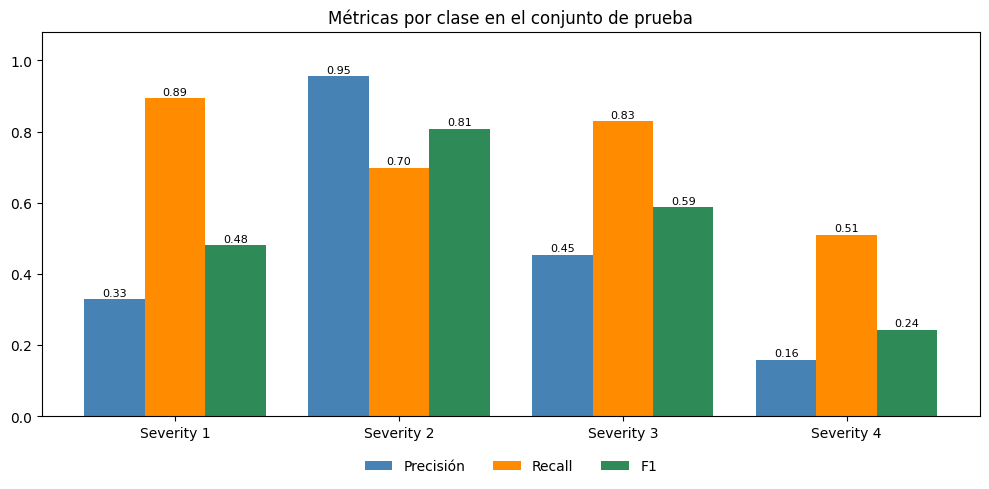

In [37]:
# Precisión, recall y F1 por clase
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(por_clase_rf))
for i, (m, color) in enumerate([("precisión", "steelblue"), ("recall", "darkorange"), ("F1", "seagreen")]):
    barras = ax.bar(x + (i - 1) * 0.27, por_clase_rf[m], 0.27, label=m.capitalize(), color=color)
    for b, v in zip(barras, por_clase_rf[m]):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.2f}", ha="center", fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels([f"Severity {s}" for s in por_clase_rf["Severity"]])
ax.set_ylim(0, 1.08)
ax.set_title("Métricas por clase en el conjunto de prueba")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.08), frameon=False)
plt.tight_layout()
plt.show()

> **Análisis**
>
> La gráfica hace evidente el compromiso entre precisión y recall. En las clases 1, 3 y 4 el recall (naranja) es mucho mayor que la precisión (azul): el modelo encuentra la mayoría de esos accidentes, pero también etiqueta como graves o leves algunos que en realidad son de nivel 2. En la clase 2 ocurre lo contrario. Si se quisiera un modelo más conservador, con menos falsas alarmas, se podrían suavizar los pesos de las clases minoritarias, a costa de detectar menos casos.

In [38]:
# Matriz de confusión con DataFrames de Spark
con_nombres = (pred_rf
    .withColumn("Severity_real", (F.col("label") + 1).cast("int"))
    .withColumn("Severity_predicha", (F.col("prediction") + 1).cast("int")))
clases = [1, 2, 3, 4]

matriz = (con_nombres.groupBy("Severity_real").pivot("Severity_predicha", clases).count()
          .na.fill(0).orderBy("Severity_real"))
print("Conteos (filas = real, columnas = predicha):")
matriz.show()

total_fila = sum(F.col(str(k)) for k in clases)
matriz_norm = matriz.select("Severity_real", *[F.round(F.col(str(k)) / total_fila, 3).alias(str(k)) for k in clases])
print("Proporción por clase real (cada fila suma 1):")
matriz_norm.show()

Conteos (filas = real, columnas = predicha):
+-------------+---+-----+-----+----+
|Severity_real|  1|    2|    3|   4|
+-------------+---+-----+-----+----+
|            1|583|   39|   24|   7|
|            2|834|41547|12508|4596|
|            3|325| 1167|10577| 691|
|            4| 33|  745|  179| 998|
+-------------+---+-----+-----+----+

Proporción por clase real (cada fila suma 1):
+-------------+-----+-----+-----+-----+
|Severity_real|    1|    2|    3|    4|
+-------------+-----+-----+-----+-----+
|            1|0.893| 0.06|0.037|0.011|
|            2|0.014|0.698| 0.21|0.077|
|            3|0.025|0.091|0.829|0.054|
|            4|0.017|0.381|0.092| 0.51|
+-------------+-----+-----+-----+-----+



> **Análisis**
>
> La matriz de confusión muestra en qué se equivoca el modelo. Las filas son la severidad real y las columnas la predicha; en la versión normalizada, cada fila suma 1 y la diagonal coincide con el recall de cada clase (0.893, 0.698, 0.829 y 0.510).

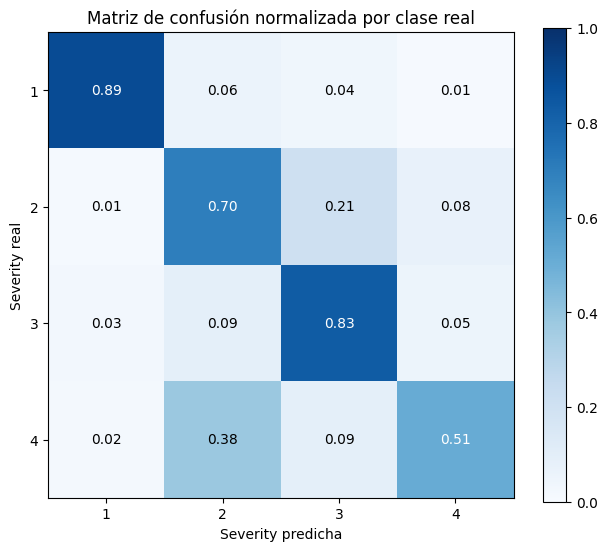

In [39]:
# Mapa de calor de la matriz de confusión normalizada
mc = matriz_norm.toPandas().set_index("Severity_real")
mc.columns = [int(c) for c in mc.columns]

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(mc.values, cmap="Blues", vmin=0, vmax=1)
for i in range(mc.shape[0]):
    for j in range(mc.shape[1]):
        v = mc.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", color="white" if v > 0.5 else "black")
ax.set_xticks(range(4))
ax.set_xticklabels(mc.columns)
ax.set_yticks(range(4))
ax.set_yticklabels(mc.index)
ax.set_xlabel("Severity predicha")
ax.set_ylabel("Severity real")
ax.set_title("Matriz de confusión normalizada por clase real")
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

> **Análisis**
>
> La diagonal oscura indica que en las clases 1, 2 y 3 la mayoría de los casos se clasifica correctamente, mientras que en la clase 4 solo la mitad. Fuera de la diagonal se ven los errores más frecuentes: cerca de 30 % de los accidentes de Severity 2 se reparten entre las otras clases, consecuencia directa de los pesos que favorecen a las clases minoritarias. Las celdas fuera de la diagonal indican hacia qué clase se desvía cada error; cuando los errores caen en niveles vecinos (por ejemplo, entre 2 y 3), es razonable, porque la frontera entre una severidad y la siguiente no siempre es clara.

### 8.4 Importancia de las variables

Random Forest mide la importancia de cada variable como la reducción de impureza que aporta, promediada sobre todos los árboles.

Árboles: 60 | Profundidad máxima: 15


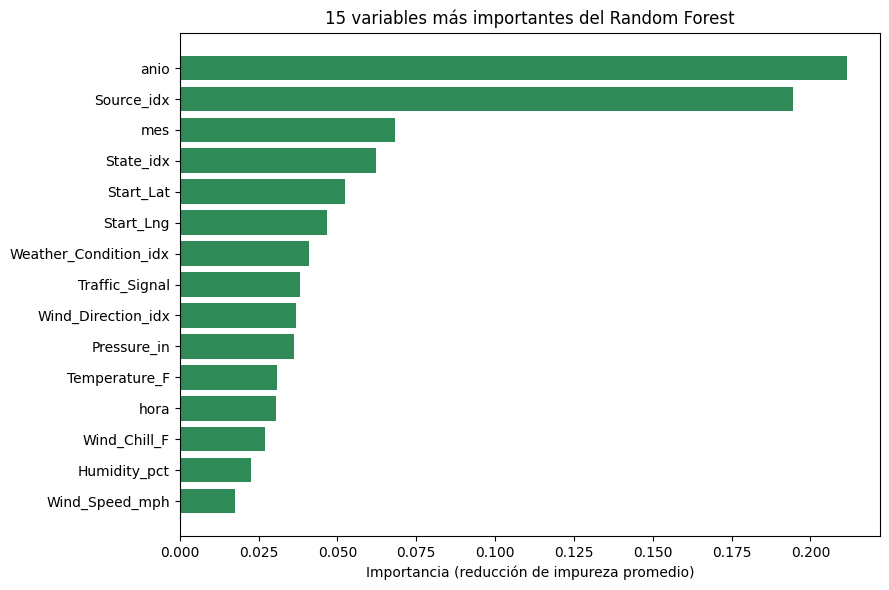

,variable,importancia
0,anio,0.211519
1,Source_idx,0.194610
2,mes,0.068222
3,State_idx,0.062310
4,Start_Lat,0.052354
5,Start_Lng,0.046771
6,Weather_Condition_idx,0.041138
7,Traffic_Signal,0.038134
8,Wind_Direction_idx,0.036912
9,Pressure_in,0.036350


In [40]:
# Importancia de las variables según el Random Forest
rf_final = mejor_rf.stages[-1]
print(f"Árboles: {rf_final.getNumTrees} | Profundidad máxima: {rf_final.getOrDefault('maxDepth')}")

imp_rf = (pd.DataFrame({"variable": cols_features, "importancia": rf_final.featureImportances.toArray()})
            .sort_values("importancia", ascending=False).head(15).reset_index(drop=True))

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(imp_rf["variable"], imp_rf["importancia"], color="seagreen")
ax.invert_yaxis()
ax.set_xlabel("Importancia (reducción de impureza promedio)")
ax.set_title("15 variables más importantes del Random Forest")
plt.tight_layout()
plt.show()
display(imp_rf)

> **Análisis**
>
> La gráfica ordena las variables según cuánto ayudan a separar las clases en los árboles del bosque. Las variables de la parte superior son las que más influyen en las predicciones del modelo.
>
> Para interpretarla conviene distinguir tres tipos de variables:
>
> - **Variables de contexto del registro**, como la fuente de los datos (Source) y el año: si aparecen arriba, indican que la severidad depende en buena medida de quién reporta el accidente y de cómo cambió esa forma de reportar con el tiempo, más que de las condiciones del accidente.
> - **Variables de ubicación y entorno vial** (estado, coordenadas, semáforos, cruces): reflejan el tipo de vía donde ocurre el accidente, que se relaciona con la velocidad del tráfico.
> - **Variables de clima**: suelen tener una importancia baja, lo que coincide con el análisis exploratorio, donde la mayoría de los accidentes ocurre con buen tiempo.
>
> La importancia por reducción de impureza indica qué variables usa el modelo, pero no si su efecto aumenta o reduce la severidad. Para eso se deben revisar las gráficas de la sección 6.1.

## Conclusiones

- **Calidad de los datos:** el dataset original tenía problemas típicos de datos reales: 117,695 registros duplicados, columnas con hasta 44 % de faltantes, categorías escritas de distintas formas y valores físicamente imposibles. Después de la limpieza se conservó el **97.73 %** de los registros (7,552,830), sin faltantes, sin duplicados y con categorías consistentes.
- **Exploración:** la severidad está muy desbalanceada (casi 80 % de los accidentes es de nivel 2). El número de accidentes depende del momento del día, del día de la semana y del estado, mientras que la proporción de accidentes graves varía según las condiciones del entorno, el clima y la fuente de los datos.
- **Modelo:** el Random Forest de MLlib, entrenado con validación cruzada de 5 folds y pesos por clase, alcanzó un **F1 ponderado de 0.752** en datos nunca vistos, muy cercano al de la validación cruzada (0.759), por lo que generaliza bien. Detecta la mayoría de los accidentes de las clases minoritarias, aunque con falsas alarmas; la clase 4 es la más difícil de predecir.
- **Trabajo futuro:** entrenar con una fracción mayor del dataset en un clúster con más recursos, probar más hiperparámetros (número de árboles, profundidad) y agregar variables derivadas, como el tipo de vía obtenido a partir de Street (autopista, avenida, calle).

# Dashboard

Link: https://public.tableau.com/views/Evidencia_BigData_M6/Dashboard1?:language=en-US&publish=yes&:sid=&:redirect=auth&:display_count=n&:origin=viz_share_link

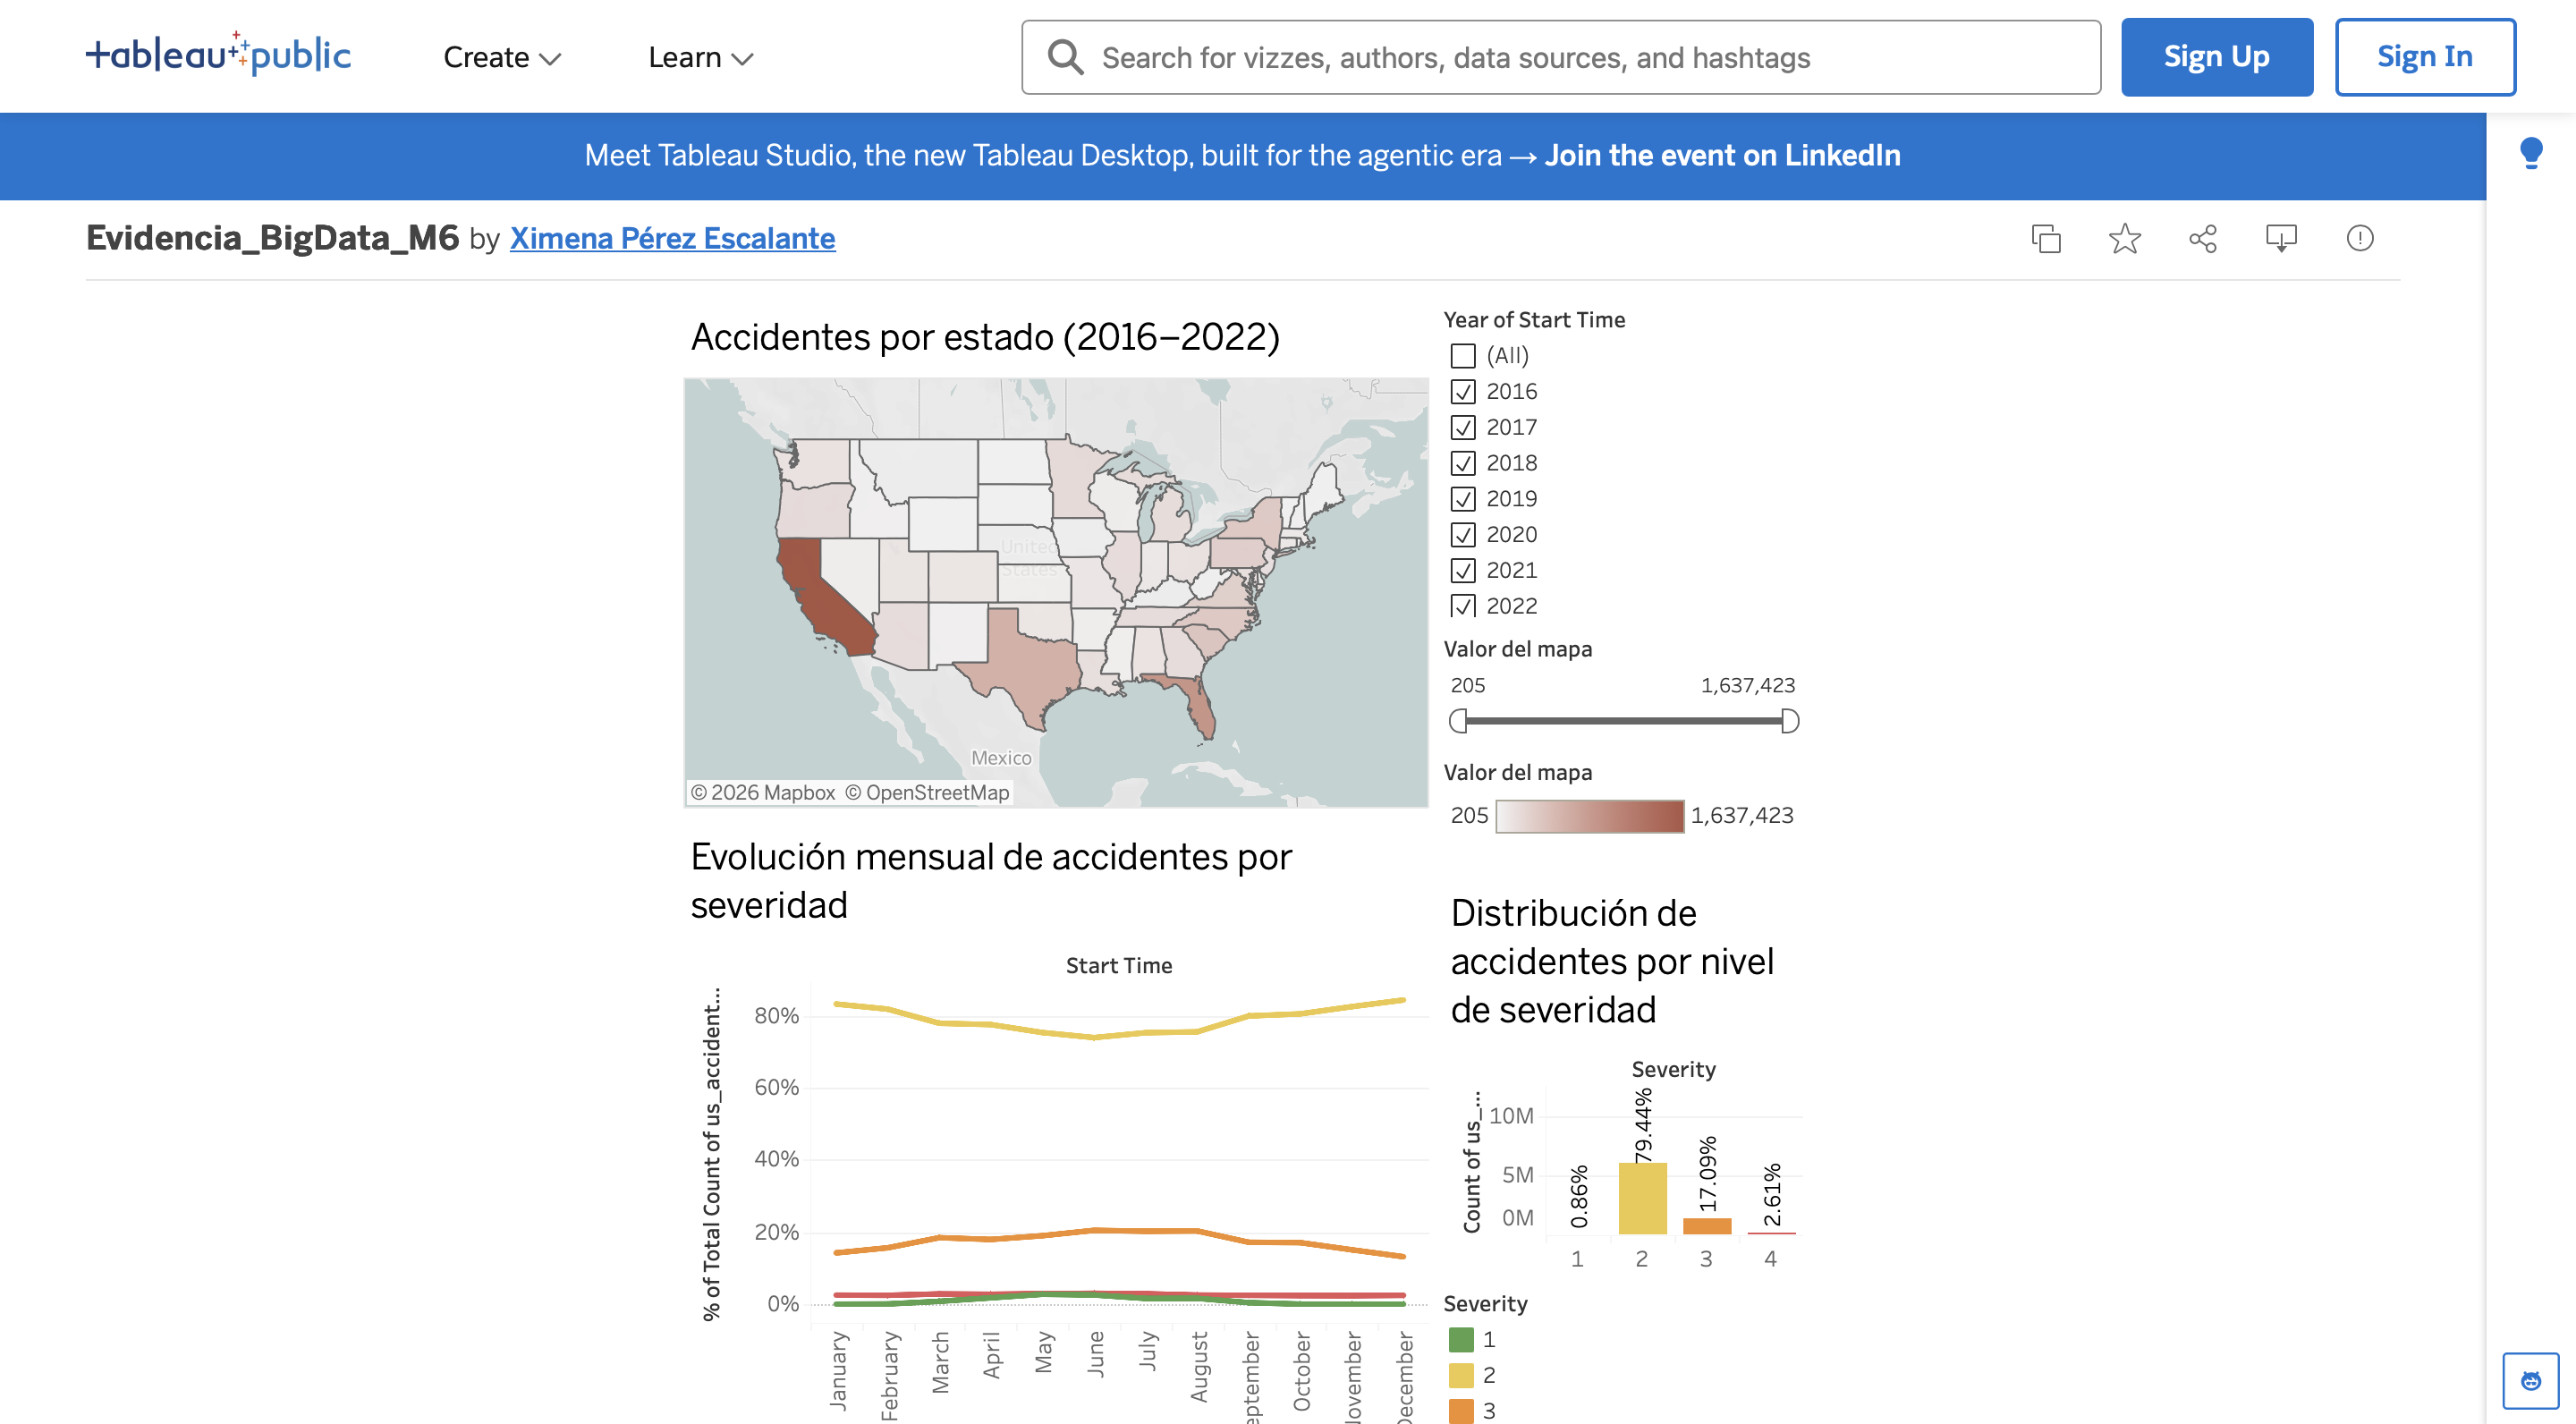

El dashboard presenta tres gráficas sobre los accidentes de tránsito registrados en Estados Unidos entre 2016 y 2022. El mapa por estado muestra dónde se concentran los accidentes. Así se distinguen los estados con más accidentes. La distribución de severidad muestra cómo se reparten los accidentes entre los cuatro niveles: alrededor del 80 % corresponde al nivel 2, un desbalance que se tomó en cuenta al entrenar el modelo de clasificación. Por último, la tendencia en el tiempo muestra la evolución mensual de los accidentes por nivel de severidad, lo que permite identificar cambios y patrones a lo largo de los años.